# Notebook 02 – Phân tích khám phá dữ liệu (EDA) Superstore

## Mục 4.1. Phân tích và khám phá dữ liệu

**Mục tiêu:** khám phá dữ liệu đã tiền xử lý để trả lời hai câu hỏi kinh doanh đầu tiên:

- **Câu hỏi 1:** sản phẩm, vùng, phân khúc nào tạo lợi nhuận và nhóm nào gây lỗ?
- **Câu hỏi 2:** mức giảm giá nào bắt đầu làm mất lợi nhuận?

**Đầu vào:** `data/processed/superstore_clean.csv` (9.993 dòng) và `data/processed/orders_level.csv` (5.009 đơn hàng), kết quả của Chương 3.

**Đầu ra:** 14 hình `figures/4_1_*.png`, các bảng `reports/4_1_*.csv`, `reports/4_1_insights.md`.

**Quy ước hình:** tiêu đề hình là một kết luận; trục có tên và đơn vị (USD, %, số đơn); màu **đỏ** chỉ nhóm lỗ, màu **xanh đậm** chỉ nhóm cần chú ý khác, còn lại là màu trung tính (xám).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED, FIGURES, REPORTS = ROOT / "data" / "processed", ROOT / "figures", ROOT / "reports"
for p in (FIGURES, REPORTS):
    p.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid.axis": "y"})
NEUTRAL, FOCUS, LOSS, INK = "#9AA5B1", "#1F6FB2", "#D62728", "#374151"

# Khổ hình: rộng tối đa 10 inch (giữ tỷ lệ) để khi đặt vào báo cáo (15 cm) chữ vẫn đọc được (khoảng 6,5 pt trở lên)
def fs(w, h, tran=10.0):
    k = min(1.0, tran / w)
    return (w * k, h * k)
# Tiêu đề dài tự xuống dòng để không làm hình rộng ra
import textwrap
_sup = plt.Figure.suptitle
def _sup_gon(self, t, *a, **k):
    return _sup(self, "\n".join(textwrap.fill(p, 78) for p in str(t).split("\n")), *a, **k)
plt.Figure.suptitle = _sup_gon
_tit = plt.Axes.set_title
def _tit_gon(self, label, *a, **k):
    return _tit(self, "\n".join(textwrap.fill(p, 66) for p in str(label).split("\n")), *a, **k)
plt.Axes.set_title = _tit_gon

def vn(x, nd=0):
    # Số kiểu Việt Nam: dấu chấm ngăn nghìn, dấu phẩy thập phân, dấu trừ thật (−)
    return f"{x:,.{nd}f}".replace(",", "_").replace(".", ",").replace("_", ".").replace("-", "−")

def pct(x, nd=1): return vn(x, nd) + "%"
def truc_tien(ax, axis="y"):
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(mtick.FuncFormatter(lambda v, _: vn(v)))
def luu(fig, ten):
    duong_dan = FIGURES / f"4_1_{ten}.png"
    fig.savefig(duong_dan, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
    print("Đã lưu hình:", duong_dan)
def nhan_xet(noi_dung): display(Markdown("**Nhận xét.** " + noi_dung))
def nhan_cot(ax, cot, gia_tri, dinh_dang, dx=0, **kw):
    kw.setdefault("bbox", dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.85))   # nhãn không bị đường tham chiếu cắt qua
    for c, v in zip(cot, gia_tri):
        ax.annotate(dinh_dang(v), (c, v), ha="center", va="bottom" if v >= 0 else "top", fontsize=9, zorder=5,
                    xytext=(dx, 3 if v >= 0 else -3), textcoords="offset points", **kw)

def sup(n):  # số mũ trên cho p-value rất nhỏ
    return str(n).translate(str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹"))
def pv(p):
    if p >= 0.001: return vn(p, 3)
    e = int(np.floor(np.log10(p))); return f"{vn(p / 10 ** e, 2)} × 10{sup(e)}"

ket_qua = {}  # gom các con số để viết insight và đối chiếu ở cuối

### Đọc dữ liệu

In [2]:
df = pd.read_csv(PROCESSED / "superstore_clean.csv", encoding="utf-8-sig", dtype={"Postal Code": str}, parse_dates=["Order Date", "Ship Date"])
orders = pd.read_csv(PROCESSED / "orders_level.csv", encoding="utf-8-sig", parse_dates=["Order Date"])
assert df.shape == (9993, 33) and len(orders) == 5009, "Dữ liệu đầu vào không đúng kích thước"

tong_sales, tong_profit = df["Sales"].sum(), df["Profit"].sum()
bien_cty = tong_profit / tong_sales
ket_qua.update(tong_sales=tong_sales, tong_profit=tong_profit, bien_cty=bien_cty)
print(f"Số dòng: {len(df):,} | số đơn: {len(orders):,} | Năm: {df['Order Year'].min()}–{df['Order Year'].max()}".replace(",", "."))
print(f"Tổng Sales: {vn(tong_sales)} USD | tổng Profit: {vn(tong_profit)} USD | biên lợi nhuận toàn công ty: {pct(100 * bien_cty)}")

def tong_hop(nhom):
    # Bảng Sales, Profit, biên lợi nhuận gộp (tổng Profit / tổng Sales) và tỷ trọng theo một cột nhóm
    g = df.groupby(nhom).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    g["Profit Margin (%)"] = 100 * g["Profit"] / g["Sales"]
    g["Tỷ trọng Sales (%)"] = 100 * g["Sales"] / g["Sales"].sum()
    g["Tỷ trọng Profit (%)"] = 100 * g["Profit"] / g["Profit"].sum()
    return g

Số dòng: 9.993 | số đơn: 5.009 | Năm: 2016–2019
Tổng Sales: 2.296.919 USD | tổng Profit: 286.409 USD | biên lợi nhuận toàn công ty: 12,5%


## 1. Phân tích đơn biến

**Độ lệch (skewness)** đo mức bất đối xứng của phân phối: 0 là đối xứng, số dương lớn là lệch phải (đa số giá trị nhỏ, một số ít rất lớn).

In [3]:
bien_don = ["Sales", "Profit", "Discount", "Quantity"]
def mo_ta(s):
    return pd.Series({"count": s.count(), "mean": s.mean(), "median": s.median(), "std": s.std(), "min": s.min(),
                      "Q1": s.quantile(0.25), "Q3": s.quantile(0.75), "max": s.max(), "skewness": s.skew()})
thong_ke = pd.DataFrame({c: mo_ta(df[c]) for c in bien_don}).T
thong_ke.index.name = "Biến"
thong_ke.round(4).to_csv(REPORTS / "4_1_descriptive_stats.csv", encoding="utf-8-sig")
display(thong_ke.round(3))
print("Đã lưu:", REPORTS / "4_1_descriptive_stats.csv")

,count,mean,median,std,min,Q1,Q3,max,skewness
Biến,,,,,,,,,
Sales,9993.0,229.853,54.480,623.276,0.444,17.280,209.940,22638.480,12.972
Profit,9993.0,28.661,8.671,234.271,-6599.978,1.731,29.364,8399.976,7.561
Discount,9993.0,0.156,0.200,0.206,0.000,0.000,0.200,0.800,1.685
Quantity,9993.0,3.790,3.000,2.225,1.000,2.000,5.000,14.000,1.278


Đã lưu: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/reports/4_1_descriptive_stats.csv


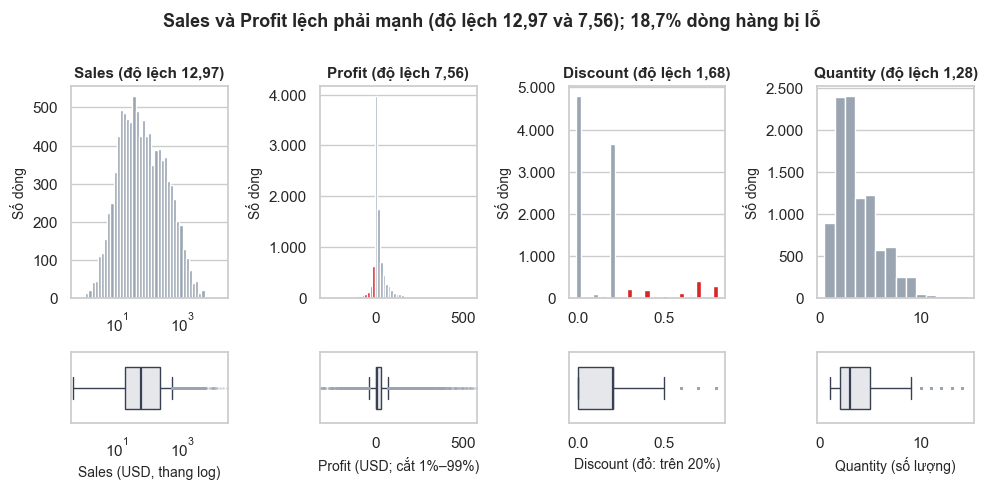

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_01_univariate_grid.png


**Nhận xét.** Sales lệch phải rất mạnh (độ lệch 12,97): trung bình 229,85 USD cao gấp 4,2 lần trung vị 54,48 USD, nghĩa là vài đơn giá trị rất lớn (tới 22.638 USD) kéo trung bình lên. Profit cũng lệch phải (7,56) với trung vị chỉ 8,67 USD và có 1.870 dòng (18,7%) bị lỗ. 48,0% dòng không giảm giá và 13,9% dòng giảm giá trên 20%.

In [4]:
fig, axes = plt.subplots(2, 4, figsize=fs(16, 7.8), gridspec_kw={"height_ratios": [3, 1]})
def ve_hop(ax, x, nguong=None):
    ax.boxplot(x, vert=False, widths=0.6, patch_artist=True, boxprops=dict(facecolor="#E5E7EB", edgecolor=INK),
               medianprops=dict(color=INK, lw=1.6), whiskerprops=dict(color=INK), capprops=dict(color=INK),
               flierprops=dict(marker="o", markersize=2, markerfacecolor=NEUTRAL, markeredgecolor="none", alpha=0.4))
    ax.set_yticks([])

# Sales: thang log trên trục x
s = df["Sales"]
axes[0, 0].hist(s, bins=np.logspace(np.log10(s.min()), np.log10(s.max()), 50), color=NEUTRAL)
axes[0, 0].set_xscale("log"); ve_hop(axes[1, 0], s); axes[1, 0].set_xscale("log")
axes[0, 0].set_xlim(s.min() * 0.9, s.max() * 1.1); axes[1, 0].set_xlim(*axes[0, 0].get_xlim())
axes[1, 0].set_xlabel("Sales (USD, thang log)")
axes[0, 0].set_title(f"Sales (độ lệch {vn(s.skew(), 2)})")

# Profit: hiển thị từ phân vị 1% đến 99%, phần âm tô đỏ
p_ = df["Profit"]; lo, hi = p_.quantile(0.01), p_.quantile(0.99)
dem, mep, cot = axes[0, 1].hist(p_, bins=60, range=(lo, hi), color=NEUTRAL)[0:3]
for rect in cot:
    if rect.get_x() + rect.get_width() / 2 < 0: rect.set_facecolor(LOSS)
ve_hop(axes[1, 1], p_); axes[0, 1].set_xlim(lo, hi); axes[1, 1].set_xlim(lo, hi)
axes[1, 1].set_xlabel("Profit (USD; cắt 1%–99%)")
axes[0, 1].set_title(f"Profit (độ lệch {vn(p_.skew(), 2)})")

# Discount: các mức rời rạc
d_ = df["Discount"].value_counts().sort_index()
axes[0, 2].bar(d_.index, d_.values, width=0.03, color=[NEUTRAL if i <= 0.2 else LOSS for i in d_.index])
ve_hop(axes[1, 2], df["Discount"]); axes[1, 2].set_xlim(axes[0, 2].get_xlim())
axes[1, 2].set_xlabel("Discount (đỏ: trên 20%)")
axes[0, 2].set_title(f"Discount (độ lệch {vn(df['Discount'].skew(), 2)})")

# Quantity
axes[0, 3].hist(df["Quantity"], bins=np.arange(0.5, 15.5, 1), color=NEUTRAL)
ve_hop(axes[1, 3], df["Quantity"]); axes[1, 3].set_xlim(axes[0, 3].get_xlim())
axes[1, 3].set_xlabel("Quantity (số lượng)")
axes[0, 3].set_title(f"Quantity (độ lệch {vn(df['Quantity'].skew(), 2)})")

for ax in axes[0]:
    ax.set_ylabel("Số dòng"); truc_tien(ax, "y")
n_lo = int((df["Profit"] < 0).sum()); ty_le_lo = 100 * n_lo / len(df)
fig.suptitle(f"Sales và Profit lệch phải mạnh (độ lệch {vn(s.skew(), 2)} và {vn(p_.skew(), 2)}); {pct(ty_le_lo)} dòng hàng bị lỗ", fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
luu(fig, "01_univariate_grid")
ket_qua.update(skew_sales=s.skew(), skew_profit=p_.skew(), n_lo=n_lo, ty_le_lo=ty_le_lo)
nhan_xet(f"Sales lệch phải rất mạnh (độ lệch {vn(s.skew(), 2)}): trung bình {vn(s.mean(), 2)} USD cao gấp {vn(s.mean() / s.median(), 1)} lần trung vị {vn(s.median(), 2)} USD, "
         f"nghĩa là vài đơn giá trị rất lớn (tới {vn(s.max())} USD) kéo trung bình lên. Profit cũng lệch phải ({vn(p_.skew(), 2)}) với trung vị chỉ {vn(p_.median(), 2)} USD và có "
         f"{vn(n_lo)} dòng ({pct(ty_le_lo)}) bị lỗ. {pct(100 * (df['Discount'] == 0).mean())} dòng không giảm giá và {pct(100 * (df['Discount'] > 0.2).mean())} dòng giảm giá trên 20%.")

## 2. Phân tích theo thời gian

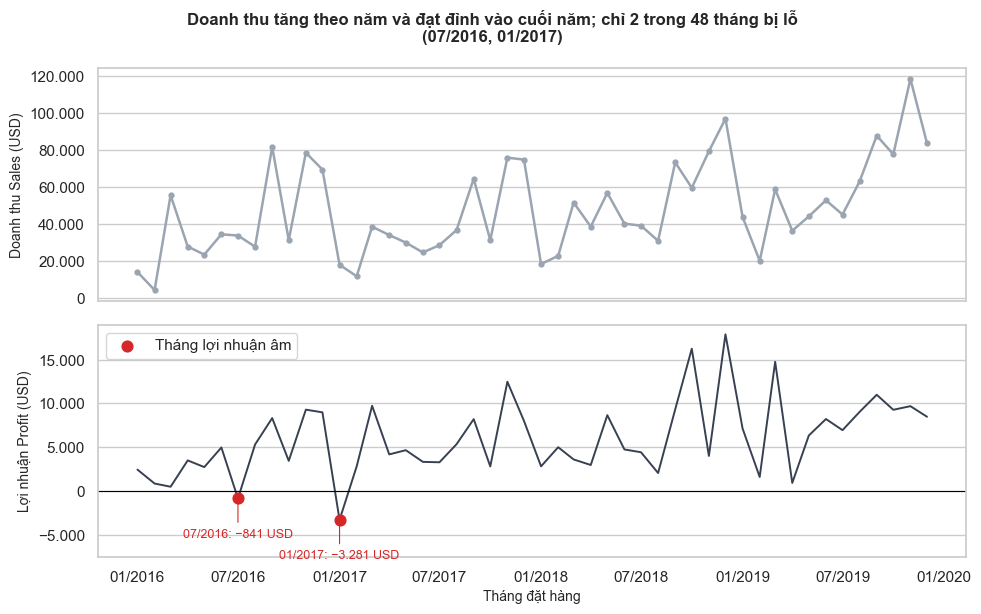

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_02_monthly_trend.png


**Nhận xét.** Trong 48 tháng chỉ có 2 tháng lợi nhuận âm (07/2016, 01/2017, thấp nhất −3.281 USD). Doanh thu tháng cao nhất là 11/2019 với 118.448 USD, gấp 3,0 lần tháng trung vị (39.803 USD).

In [5]:
df["Tháng"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
thang = df.groupby("Tháng").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
thang_lo = thang[thang["Profit"] < 0]

fig, (a1, a2) = plt.subplots(2, 1, figsize=fs(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
a1.plot(thang.index, thang["Sales"], color=NEUTRAL, marker="o", ms=3.5, lw=1.8)
a1.set_ylabel("Doanh thu Sales (USD)"); truc_tien(a1)
a2.plot(thang.index, thang["Profit"], color=INK, lw=1.4)
a2.scatter(thang_lo.index, thang_lo["Profit"], color=LOSS, s=60, zorder=3, label="Tháng lợi nhuận âm")
a2.axhline(0, color="black", lw=0.8)
for t, v in thang_lo["Profit"].items():
    a2.annotate(f"{t:%m/%Y}: {vn(v)} USD", (t, v), xytext=(0, -28), textcoords="offset points", ha="center", color=LOSS, fontsize=9,
                arrowprops=dict(arrowstyle="-", color=LOSS, lw=0.8))
a2.set_ylabel("Lợi nhuận Profit (USD)"); truc_tien(a2); a2.legend(loc="upper left"); a2.set_ylim(bottom=thang["Profit"].min() * 2.3)
a2.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7))); a2.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
a2.set_xlabel("Tháng đặt hàng")
thang_dinh = thang["Sales"].idxmax()
fig.suptitle(f"Doanh thu tăng theo năm và đạt đỉnh vào cuối năm; chỉ {len(thang_lo)} trong {len(thang)} tháng bị lỗ ({', '.join(f'{t:%m/%Y}' for t in thang_lo.index)})", fontsize=12, fontweight="bold")
fig.tight_layout()
luu(fig, "02_monthly_trend")
ket_qua.update(thang_lo=[f"{t:%m/%Y}" for t in thang_lo.index], thang_dinh=f"{thang_dinh:%m/%Y}", sales_thang_dinh=thang.loc[thang_dinh, "Sales"])
nhan_xet(f"Trong {len(thang)} tháng chỉ có {len(thang_lo)} tháng lợi nhuận âm ({', '.join(f'{t:%m/%Y}' for t in thang_lo.index)}, thấp nhất {vn(thang_lo['Profit'].min())} USD). "
         f"Doanh thu tháng cao nhất là {thang_dinh:%m/%Y} với {vn(thang.loc[thang_dinh, 'Sales'])} USD, gấp {vn(thang.loc[thang_dinh, 'Sales'] / thang['Sales'].median(), 1)} lần tháng trung vị ({vn(thang['Sales'].median())} USD).")

,Sales,Profit,Profit Margin (%),Tăng trưởng Sales so với năm trước (%)
Năm,,,,
2016,483966.13,49556.03,10.24,NaN
2017,470532.51,61618.60,13.10,-2.78
2018,609205.60,81795.17,13.43,29.47
2019,733215.26,93439.27,12.74,20.36


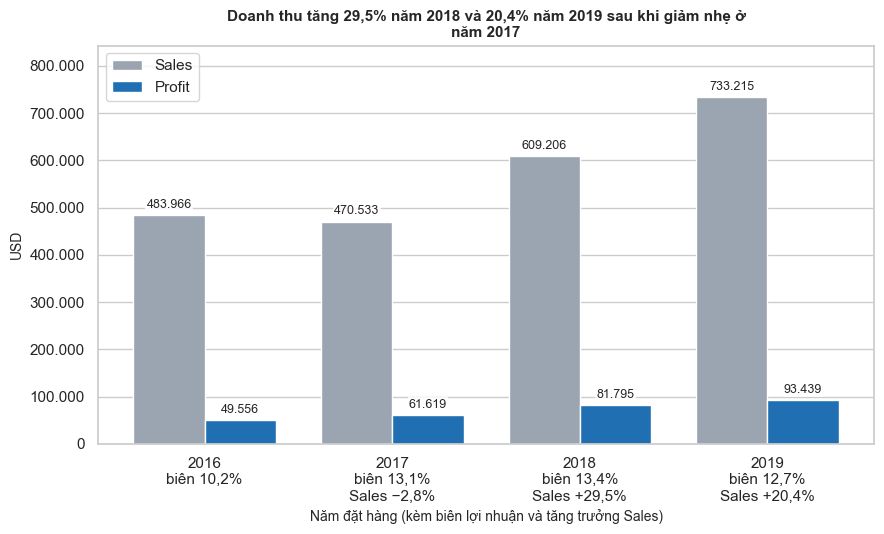

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_03_year_summary.png


**Nhận xét.** Sales giảm 2,8% năm 2017 rồi tăng 29,5% (2018) và 20,4% (2019); Profit tăng đều từ 49.556 lên 93.439 USD. Biên lợi nhuận tăng từ 10,2% (2016) lên 13,4% (2018) rồi giảm nhẹ còn 12,7% (2019), tức năm 2019 bán nhiều hơn nhưng lãi trên mỗi USD doanh thu thấp hơn năm 2018.

In [6]:
nam = df.groupby("Order Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
nam["Profit Margin (%)"] = 100 * nam["Profit"] / nam["Sales"]
nam["Tăng trưởng Sales so với năm trước (%)"] = nam["Sales"].pct_change() * 100
nam.index.name = "Năm"
nam.round(2).to_csv(REPORTS / "4_1_year_summary.csv", encoding="utf-8-sig")
display(nam.round(2))
ket_qua["nam"] = nam

fig, ax = plt.subplots(figsize=fs(9, 5.5))
x = np.arange(len(nam)); w = 0.38
b1 = ax.bar(x - w / 2, nam["Sales"], w, color=NEUTRAL, label="Sales")
b2 = ax.bar(x + w / 2, nam["Profit"], w, color=FOCUS, label="Profit")
nhan_cot(ax, x - w / 2, nam["Sales"], lambda v: vn(v)); nhan_cot(ax, x + w / 2, nam["Profit"], lambda v: vn(v))
nhan_nam = []
for nm, g, m_ in zip(nam.index, nam["Tăng trưởng Sales so với năm trước (%)"], nam["Profit Margin (%)"]):
    nhan_nam.append(f"{nm}\nbiên {pct(m_)}" + ("" if np.isnan(g) else f"\nSales {'+' if g >= 0 else ''}{pct(g)}"))
ax.set_xticks(x); ax.set_xticklabels(nhan_nam); ax.set_ylim(0, nam["Sales"].max() * 1.15); truc_tien(ax)
ax.set_xlabel("Năm đặt hàng (kèm biên lợi nhuận và tăng trưởng Sales)"); ax.set_ylabel("USD"); ax.legend(loc="upper left")
g18, g19 = nam.loc[2018, "Tăng trưởng Sales so với năm trước (%)"], nam.loc[2019, "Tăng trưởng Sales so với năm trước (%)"]
ax.set_title(f"Doanh thu tăng {pct(g18)} năm 2018 và {pct(g19)} năm 2019 sau khi giảm nhẹ ở năm 2017")
fig.tight_layout()
luu(fig, "03_year_summary")
nhan_xet(f"Sales giảm {pct(-nam.loc[2017, 'Tăng trưởng Sales so với năm trước (%)'])} năm 2017 rồi tăng {pct(g18)} (2018) và {pct(g19)} (2019); Profit tăng đều từ {vn(nam.loc[2016, 'Profit'])} lên {vn(nam.loc[2019, 'Profit'])} USD. "
         f"Biên lợi nhuận tăng từ {pct(nam.loc[2016, 'Profit Margin (%)'])} (2016) lên {pct(nam.loc[2018, 'Profit Margin (%)'])} (2018) rồi giảm nhẹ còn {pct(nam.loc[2019, 'Profit Margin (%)'])} (2019), tức năm 2019 bán nhiều hơn nhưng lãi trên mỗi USD doanh thu thấp hơn năm 2018.")

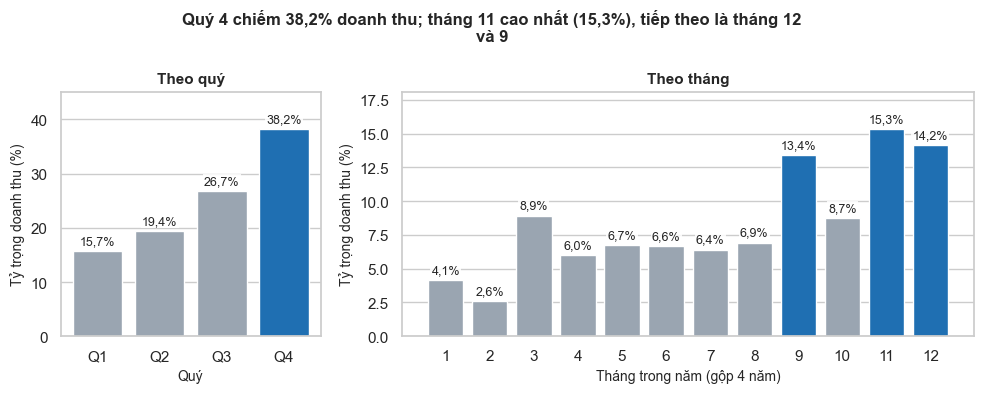

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_04_seasonality.png


**Nhận xét.** Doanh thu tập trung vào nửa cuối năm: Q3 và Q4 chiếm 65,0% (Q4 riêng 38,2%, Q1 chỉ 15,7%). Ba tháng cao nhất là 11, 12 và 9 (lần lượt 15,3%, 14,2%, 13,4%), gộp lại 42,9% doanh thu cả năm.

In [7]:
quy = df.groupby("Order Quarter")["Sales"].sum(); quy_tt = 100 * quy / quy.sum()
thg = df.groupby("Order Month")["Sales"].sum(); thg_tt = 100 * thg / thg.sum()
top_thang = thg_tt.nlargest(3)
mua_vu = pd.concat([pd.DataFrame({"Loại": "Quý", "Kỳ": [f"Q{q}" for q in quy.index], "Sales": quy.values, "Tỷ trọng Sales (%)": quy_tt.values}),
                    pd.DataFrame({"Loại": "Tháng", "Kỳ": [f"Tháng {m}" for m in thg.index], "Sales": thg.values, "Tỷ trọng Sales (%)": thg_tt.values})])
mua_vu.round(2).to_csv(REPORTS / "4_1_seasonality.csv", index=False, encoding="utf-8-sig")

fig, (a1, a2) = plt.subplots(1, 2, figsize=fs(13, 5.2), gridspec_kw={"width_ratios": [1, 2.2]})
q_dinh = quy_tt.idxmax()
a1.bar([f"Q{q}" for q in quy_tt.index], quy_tt.values, color=[FOCUS if q == q_dinh else NEUTRAL for q in quy_tt.index])
nhan_cot(a1, range(len(quy_tt)), quy_tt.values, lambda v: pct(v))
a1.set_ylabel("Tỷ trọng doanh thu (%)"); a1.set_xlabel("Quý"); a1.set_ylim(0, quy_tt.max() * 1.18); a1.set_title("Theo quý")
a2.bar([str(m) for m in thg_tt.index], thg_tt.values, color=[FOCUS if m in top_thang.index else NEUTRAL for m in thg_tt.index])
nhan_cot(a2, range(len(thg_tt)), thg_tt.values, lambda v: pct(v))
a2.set_ylabel("Tỷ trọng doanh thu (%)"); a2.set_xlabel("Tháng trong năm (gộp 4 năm)"); a2.set_ylim(0, thg_tt.max() * 1.18); a2.set_title("Theo tháng")
fig.suptitle(f"Quý {q_dinh} chiếm {pct(quy_tt.max())} doanh thu; tháng {top_thang.index[0]} cao nhất ({pct(top_thang.iloc[0])}), tiếp theo là tháng {top_thang.index[1]} và {top_thang.index[2]}", fontsize=12, fontweight="bold")
fig.tight_layout()
luu(fig, "04_seasonality")
ket_qua.update(quy_tt=quy_tt, thg_tt=thg_tt, top_thang=top_thang)
nhan_xet(f"Doanh thu tập trung vào nửa cuối năm: Q3 và Q4 chiếm {pct(quy_tt[3] + quy_tt[4])} (Q4 riêng {pct(quy_tt[4])}, Q1 chỉ {pct(quy_tt[1])}). "
         f"Ba tháng cao nhất là {top_thang.index[0]}, {top_thang.index[1]} và {top_thang.index[2]} (lần lượt {pct(top_thang.iloc[0])}, {pct(top_thang.iloc[1])}, {pct(top_thang.iloc[2])}), gộp lại {pct(top_thang.sum())} doanh thu cả năm.")

## 3. Phân tích theo nhóm (trả lời Câu hỏi 1)

**Profit Margin** (biên lợi nhuận) ở đây là tổng Profit chia tổng Sales của nhóm, tức lãi trên mỗi USD doanh thu.

,Nhóm biến,Nhóm,Sales,Profit,Profit Margin (%),Tỷ trọng Sales (%),Tỷ trọng Profit (%)
0,Region,Central,501239.89,39706.36,7.92,21.82,13.86
1,Region,East,678499.87,91534.84,13.49,29.54,31.96
2,Region,South,391721.90,46749.43,11.93,17.05,16.32
3,Region,West,725457.82,108418.45,14.94,31.58,37.85
0,Segment,Consumer,1161401.34,134119.21,11.55,50.56,46.83
1,Segment,Corporate,706146.37,91979.13,13.03,30.74,32.11
2,Segment,Home Office,429371.78,60310.74,14.05,18.69,21.06
0,Category,Furniture,741718.42,18463.33,2.49,32.29,6.45
1,Category,Office Supplies,719047.03,122490.80,17.04,31.30,42.77
2,Category,Technology,836154.03,145454.95,17.40,36.40,50.79


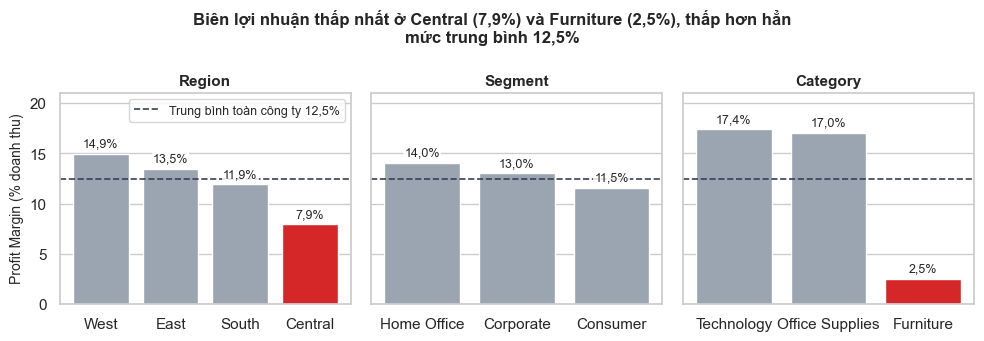

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_05_margin_by_group.png


**Nhận xét.** Theo vùng, West có biên cao nhất (14,9%) còn Central thấp nhất (7,9%); theo ngành hàng, Technology (17,4%) và Office Supplies (17,0%) gần gấp bảy lần Furniture (2,5%). Theo phân khúc, Home Office (14,0%) cao hơn Consumer (11,5%) nhưng chênh lệch nhỏ.

In [8]:
tt = {c: tong_hop(c) for c in ["Region", "Segment", "Category"]}
bang_nhom = pd.concat([t.reset_index().rename(columns={c: "Nhóm"}).assign(**{"Nhóm biến": c}) for c, t in tt.items()])
bang_nhom = bang_nhom[["Nhóm biến", "Nhóm", "Sales", "Profit", "Profit Margin (%)", "Tỷ trọng Sales (%)", "Tỷ trọng Profit (%)"]]
bang_nhom.round(2).to_csv(REPORTS / "4_1_group_summary.csv", index=False, encoding="utf-8-sig")
display(bang_nhom.round(2))
ket_qua["tt"] = tt

fig, axes = plt.subplots(1, 3, figsize=fs(15, 5.2), sharey=True)
nguong_thap = 0.8 * bien_cty * 100   # nhóm có biên thấp hơn ít nhất 20% so với mức chung được tô đỏ
for ax, (c, t) in zip(axes, tt.items()):
    t = t.sort_values("Profit Margin (%)", ascending=False)
    ax.bar(t.index, t["Profit Margin (%)"], color=[LOSS if v < nguong_thap else NEUTRAL for v in t["Profit Margin (%)"]])
    ax.axhline(bien_cty * 100, color=INK, ls="--", lw=1.2, label=f"Trung bình toàn công ty {pct(bien_cty * 100)}")
    if ax is axes[0]: ax.legend(loc="upper right", fontsize=9)     # chú giải một lần cho cả ba ô
    nhan_cot(ax, range(len(t)), t["Profit Margin (%)"], lambda v: pct(v))
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylim(0, 21)
axes[0].set_ylabel("Profit Margin (% doanh thu)")
tap = tt["Category"]["Profit Margin (%)"]; vung = tt["Region"]["Profit Margin (%)"]
fig.suptitle(f"Biên lợi nhuận thấp nhất ở Central ({pct(vung['Central'])}) và Furniture ({pct(tap['Furniture'])}), thấp hơn hẳn mức trung bình {pct(bien_cty * 100)}", fontsize=12, fontweight="bold")
fig.tight_layout()
luu(fig, "05_margin_by_group")
nhan_xet(f"Theo vùng, West có biên cao nhất ({pct(vung['West'])}) còn Central thấp nhất ({pct(vung['Central'])}); theo ngành hàng, Technology ({pct(tap['Technology'])}) và Office Supplies ({pct(tap['Office Supplies'])}) "
         f"gần gấp bảy lần Furniture ({pct(tap['Furniture'])}). Theo phân khúc, Home Office ({pct(tt['Segment'].loc['Home Office', 'Profit Margin (%)'])}) cao hơn Consumer ({pct(tt['Segment'].loc['Consumer', 'Profit Margin (%)'])}) nhưng chênh lệch nhỏ.")

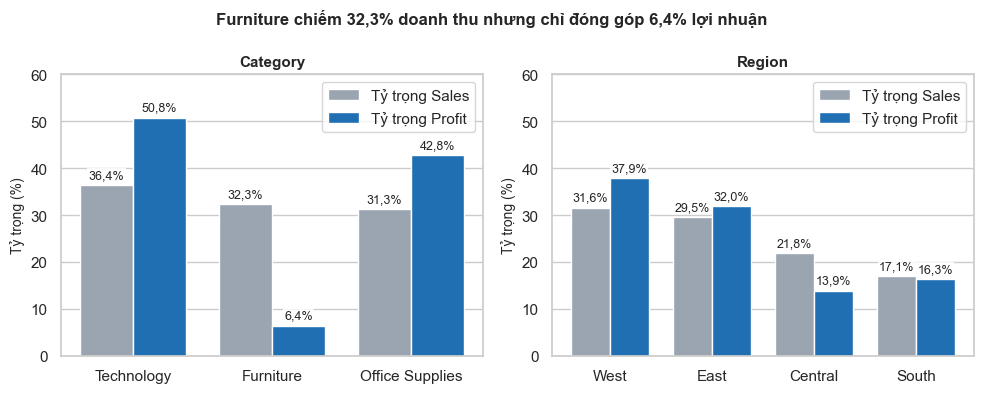

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_06_share_sales_vs_profit.png


**Nhận xét.** Technology chiếm 36,4% doanh thu và 50,8% lợi nhuận, trong khi Furniture lệch rất xa (32,3% so với 6,4%). Central đóng góp 21,8% doanh thu nhưng chỉ 13,9% lợi nhuận, còn West đóng góp 37,9% lợi nhuận với 31,6% doanh thu.

In [9]:
fig, axes = plt.subplots(1, 2, figsize=fs(13, 5.2))
for ax, c in zip(axes, ["Category", "Region"]):
    t = tt[c].sort_values("Tỷ trọng Sales (%)", ascending=False); x = np.arange(len(t)); w = 0.38
    ax.bar(x - w / 2, t["Tỷ trọng Sales (%)"], w, color=NEUTRAL, label="Tỷ trọng Sales")
    ax.bar(x + w / 2, t["Tỷ trọng Profit (%)"], w, color=FOCUS, label="Tỷ trọng Profit")
    nhan_cot(ax, x - w / 2, t["Tỷ trọng Sales (%)"], lambda v: pct(v)); nhan_cot(ax, x + w / 2, t["Tỷ trọng Profit (%)"], lambda v: pct(v))
    ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_ylabel("Tỷ trọng (%)"); ax.set_ylim(0, 60); ax.set_title(c); ax.legend()
fu = tt["Category"].loc["Furniture"]
fig.suptitle(f"Furniture chiếm {pct(fu['Tỷ trọng Sales (%)'])} doanh thu nhưng chỉ đóng góp {pct(fu['Tỷ trọng Profit (%)'])} lợi nhuận", fontsize=12, fontweight="bold")
fig.tight_layout()
luu(fig, "06_share_sales_vs_profit")
ce = tt["Region"].loc["Central"]
nhan_xet(f"Technology chiếm {pct(tt['Category'].loc['Technology', 'Tỷ trọng Sales (%)'])} doanh thu và {pct(tt['Category'].loc['Technology', 'Tỷ trọng Profit (%)'])} lợi nhuận, trong khi Furniture lệch rất xa ({pct(fu['Tỷ trọng Sales (%)'])} so với {pct(fu['Tỷ trọng Profit (%)'])}). "
         f"Central đóng góp {pct(ce['Tỷ trọng Sales (%)'])} doanh thu nhưng chỉ {pct(ce['Tỷ trọng Profit (%)'])} lợi nhuận, còn West đóng góp {pct(tt['Region'].loc['West', 'Tỷ trọng Profit (%)'])} lợi nhuận với {pct(tt['Region'].loc['West', 'Tỷ trọng Sales (%)'])} doanh thu.")

,Sales,Profit,Profit Margin (%),Tỷ trọng Sales (%),Tỷ trọng Profit (%)
Sub-Category,,,,,
Tables,206965.53,-17725.48,-8.56,9.01,-6.19
Bookcases,114880.00,-3472.56,-3.02,5.00,-1.21
Supplies,46673.54,-1189.10,-2.55,2.03,-0.42
Fasteners,3024.28,949.52,31.40,0.13,0.33
Machines,189238.63,3384.76,1.79,8.24,1.18
Labels,12486.31,5546.25,44.42,0.54,1.94
Art,27118.79,6527.79,24.07,1.18,2.28
Envelopes,16476.40,6964.18,42.27,0.72,2.43
Furnishings,91705.16,13059.14,14.24,3.99,4.56


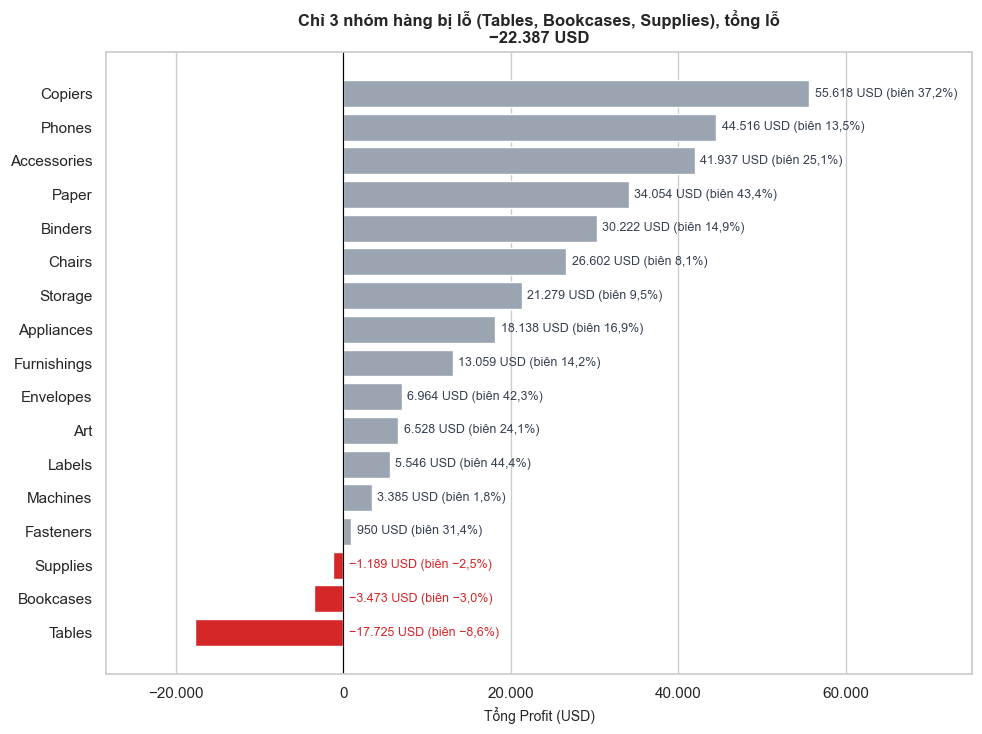

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_07_subcategory_profit.png


**Nhận xét.** 3/17 nhóm hàng bị lỗ, riêng Tables lỗ −17.725 USD, chiếm 79,2% tổng lỗ của các nhóm này. Ngược lại Copiers (55.618 USD, biên 37,2%) và Phones (44.516 USD) sinh lời nhiều nhất.

In [10]:
sub = tong_hop("Sub-Category").sort_values("Profit")
sub.index.name = "Sub-Category"
sub.round(2).to_csv(REPORTS / "4_1_subcategory_summary.csv", encoding="utf-8-sig")
sub_lo = sub[sub["Profit"] < 0]
display(sub.round(2))

fig, ax = plt.subplots(figsize=fs(10, 7.5))
ax.barh(sub.index, sub["Profit"], color=[LOSS if v < 0 else NEUTRAL for v in sub["Profit"]])
for i, (v, m_) in enumerate(zip(sub["Profit"], sub["Profit Margin (%)"])):
    ax.text(max(v, 0) + 0.012 * sub["Profit"].max(), i, f"{vn(v)} USD (biên {pct(m_)})", va="center", ha="left", fontsize=9, color=LOSS if v < 0 else INK)
ax.axvline(0, color="black", lw=0.8); truc_tien(ax, "x")
ax.set_xlim(sub["Profit"].min() * 1.6, sub["Profit"].max() * 1.35)
ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
ax.set_xlabel("Tổng Profit (USD)"); ax.set_ylabel("")
ax.set_title(f"Chỉ {len(sub_lo)} nhóm hàng bị lỗ ({', '.join(sub_lo.index)}), tổng lỗ {vn(sub_lo['Profit'].sum())} USD", fontsize=12)
fig.tight_layout()
luu(fig, "07_subcategory_profit")
ket_qua["sub_lo"] = sub_lo
nhan_xet(f"{len(sub_lo)}/17 nhóm hàng bị lỗ, riêng Tables lỗ {vn(sub.loc['Tables', 'Profit'])} USD, chiếm {pct(100 * sub.loc['Tables', 'Profit'] / sub_lo['Profit'].sum())} tổng lỗ của các nhóm này. "
         f"Ngược lại Copiers ({vn(sub.loc['Copiers', 'Profit'])} USD, biên {pct(sub.loc['Copiers', 'Profit Margin (%)'])}) và Phones ({vn(sub.loc['Phones', 'Profit'])} USD) sinh lời nhiều nhất.")

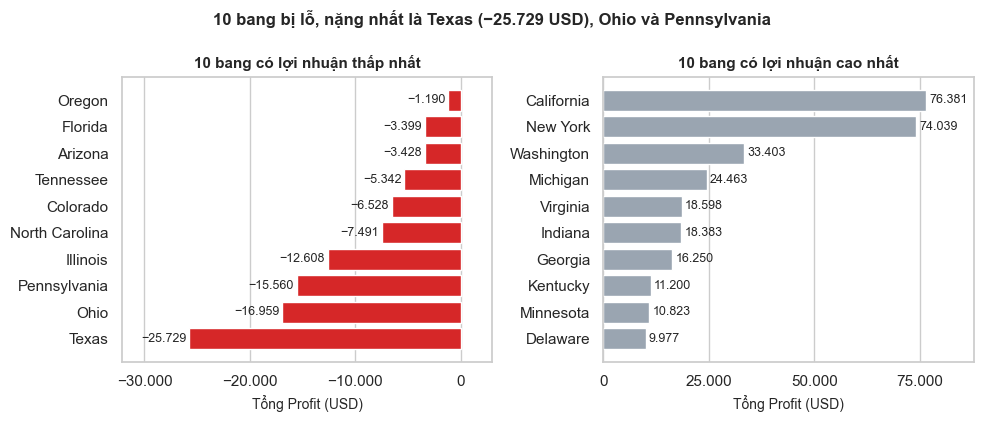

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_08_state_top_bottom.png


**Nhận xét.** 10/49 bang có tổng Profit âm; ba bang lỗ nặng nhất là Texas (−25.729), Ohio (−16.959) và Pennsylvania (−15.560 USD), tổng lỗ của 10 bang là −98.235 USD. California (76.381) và New York (74.039 USD) là hai bang lãi nhiều nhất.

In [11]:
bang = df.groupby("State").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).sort_values("Profit")
bang["Profit Margin (%)"] = 100 * bang["Profit"] / bang["Sales"]
bang.round(2).to_csv(REPORTS / "4_1_state_profit.csv", encoding="utf-8-sig")
n_bang_lo = int((bang["Profit"] < 0).sum())
xau, tot = bang.head(10), bang.tail(10)

fig, (a1, a2) = plt.subplots(1, 2, figsize=fs(14, 6))
a1.barh(xau.index, xau["Profit"], color=[LOSS if v < 0 else NEUTRAL for v in xau["Profit"]])
a2.barh(tot.index, tot["Profit"], color=NEUTRAL)
for ax, t in ((a1, xau), (a2, tot)):
    for i, v in enumerate(t["Profit"]):
        ax.text(v + (-0.01 if v < 0 else 0.01) * abs(t["Profit"]).max(), i, vn(v), va="center", ha="right" if v < 0 else "left", fontsize=9)
    truc_tien(ax, "x"); ax.xaxis.set_major_locator(mtick.MaxNLocator(nbins=4)); ax.set_xlabel("Tổng Profit (USD)"); ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
a1.set_xlim(xau["Profit"].min() * 1.25, 3000); a2.set_xlim(0, tot["Profit"].max() * 1.15)
a1.set_title("10 bang có lợi nhuận thấp nhất"); a2.set_title("10 bang có lợi nhuận cao nhất")
top3 = bang.head(3)
fig.suptitle(f"{n_bang_lo} bang bị lỗ, nặng nhất là {top3.index[0]} ({vn(top3['Profit'].iloc[0])} USD), {top3.index[1]} và {top3.index[2]}", fontsize=12, fontweight="bold")
fig.tight_layout()
luu(fig, "08_state_top_bottom")
ket_qua.update(n_bang_lo=n_bang_lo, bang_state=bang)
nhan_xet(f"{n_bang_lo}/{len(bang)} bang có tổng Profit âm; ba bang lỗ nặng nhất là {top3.index[0]} ({vn(top3['Profit'].iloc[0])}), {top3.index[1]} ({vn(top3['Profit'].iloc[1])}) và {top3.index[2]} ({vn(top3['Profit'].iloc[2])} USD), "
         f"tổng lỗ của {n_bang_lo} bang là {vn(bang.loc[bang['Profit'] < 0, 'Profit'].sum())} USD. California ({vn(tot['Profit'].iloc[-1])}) và New York ({vn(tot['Profit'].iloc[-2])} USD) là hai bang lãi nhiều nhất.")

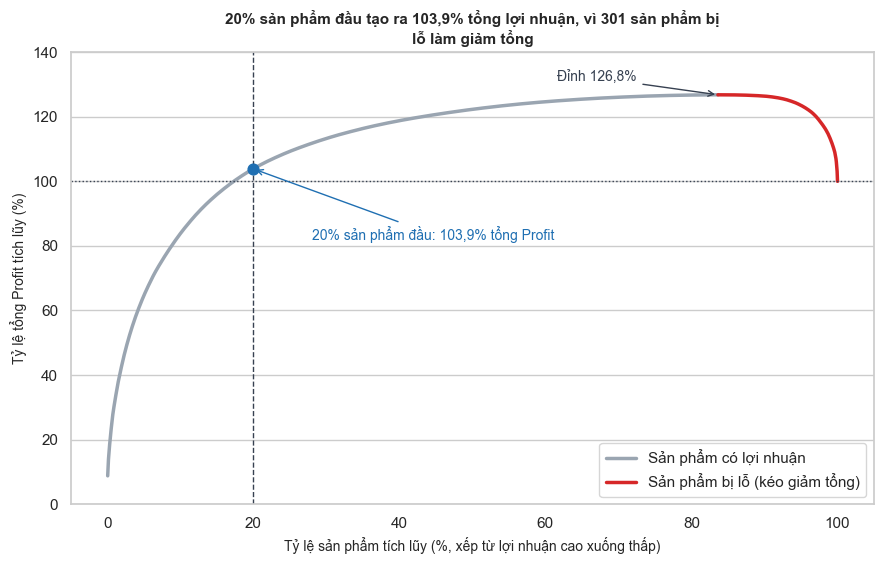

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_09_pareto.png


**Nhận xét.** Trong 1.862 sản phẩm, 372 sản phẩm đứng đầu (20%) tạo ra 103,9% tổng lợi nhuận. Đường tích lũy đạt đỉnh 126,8% rồi giảm vì 301 sản phẩm (16,2%) có tổng Profit âm, làm mất 26,8% tổng lợi nhuận. Lợi nhuận vì vậy tập trung rất cao ở một nhóm nhỏ sản phẩm.

In [12]:
sp = df.groupby("Product ID")["Profit"].sum().sort_values(ascending=False)
tich_luy = sp.cumsum() / sp.sum() * 100
ty_le_sp = np.arange(1, len(sp) + 1) / len(sp) * 100
k20 = int(round(0.2 * len(sp))); dinh = int(np.argmax(tich_luy.values)); n_sp_lo = int((sp < 0).sum())

fig, ax = plt.subplots(figsize=fs(9, 5.8))
ax.plot(ty_le_sp[:dinh + 1], tich_luy.values[:dinh + 1], color=NEUTRAL, lw=2.5, label="Sản phẩm có lợi nhuận")
ax.plot(ty_le_sp[dinh:], tich_luy.values[dinh:], color=LOSS, lw=2.5, label="Sản phẩm bị lỗ (kéo giảm tổng)")
ax.axhline(100, color=INK, ls=":", lw=1); ax.axvline(20, color=INK, ls="--", lw=1)
ax.scatter([20], [tich_luy.values[k20 - 1]], color=FOCUS, zorder=3, s=60)
ax.annotate(f"20% sản phẩm đầu: {pct(tich_luy.values[k20 - 1])} tổng Profit", (20, tich_luy.values[k20 - 1]), xytext=(28, tich_luy.values[k20 - 1] - 22), fontsize=10, color=FOCUS,
            arrowprops=dict(arrowstyle="->", color=FOCUS))
ax.annotate(f"Đỉnh {pct(tich_luy.max())}", (ty_le_sp[dinh], tich_luy.max()), xytext=(ty_le_sp[dinh] - 22, tich_luy.max() + 4), fontsize=10, color=INK, arrowprops=dict(arrowstyle="->", color=INK))
ax.set_xlabel("Tỷ lệ sản phẩm tích lũy (%, xếp từ lợi nhuận cao xuống thấp)"); ax.set_ylabel("Tỷ lệ tổng Profit tích lũy (%)"); ax.set_ylim(0, 140); ax.legend(loc="lower right")
ax.set_title(f"20% sản phẩm đầu tạo ra {pct(tich_luy.values[k20 - 1])} tổng lợi nhuận, vì {vn(n_sp_lo)} sản phẩm bị lỗ làm giảm tổng")
fig.tight_layout()
luu(fig, "09_pareto")
ket_qua.update(pareto20=tich_luy.values[k20 - 1], pareto_dinh=tich_luy.max(), n_sp=len(sp), n_sp_lo=n_sp_lo)
nhan_xet(f"Trong {vn(len(sp))} sản phẩm, {vn(k20)} sản phẩm đứng đầu (20%) tạo ra {pct(tich_luy.values[k20 - 1])} tổng lợi nhuận. Đường tích lũy đạt đỉnh {pct(tich_luy.max())} rồi giảm vì {vn(n_sp_lo)} sản phẩm ({pct(100 * n_sp_lo / len(sp))}) có tổng Profit âm, "
         f"làm mất {pct(tich_luy.max() - 100)} tổng lợi nhuận. Lợi nhuận vì vậy tập trung rất cao ở một nhóm nhỏ sản phẩm.")

## 4. Phân tích quan hệ (trả lời Câu hỏi 2)

- **Pearson** đo quan hệ **tuyến tính** giữa hai biến và nhạy với ngoại lai.
- **Spearman** đo quan hệ **đơn điệu** (cùng tăng hoặc cùng giảm, không cần theo đường thẳng) dựa trên thứ hạng nên bền với ngoại lai.

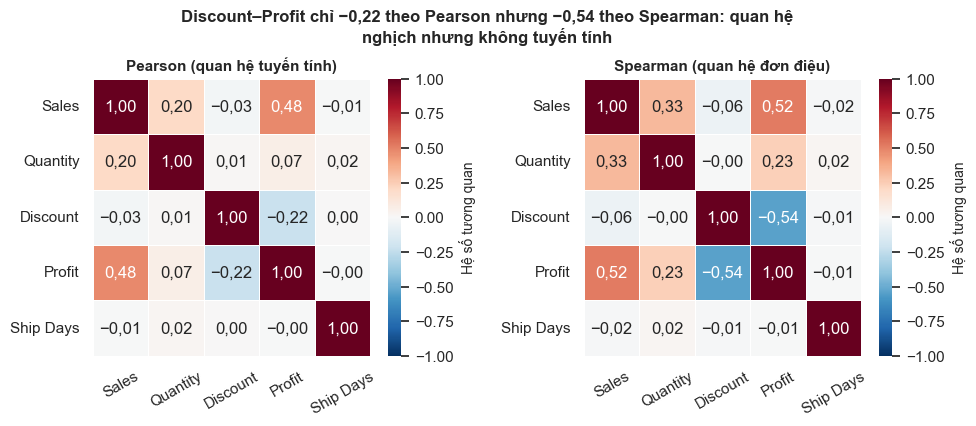

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_10_correlation.png


**Nhận xét.** Hệ số Discount–Profit là −0,22 (Pearson) và −0,54 (Spearman); Sales–Profit là 0,48 (Pearson) và 0,52 (Spearman). Ship Days gần như không liên quan tới các biến khác (|r| ≤ 0,02).

In [13]:
v5 = ["Sales", "Quantity", "Discount", "Profit", "Ship Days"]
pear, spear = df[v5].corr(), df[v5].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=fs(14, 5.8))
for ax, m_, ten in zip(axes, (pear, spear), ("Pearson (quan hệ tuyến tính)", "Spearman (quan hệ đơn điệu)")):
    sns.heatmap(m_, annot=np.vectorize(lambda v: vn(v, 2))(m_.values), fmt="", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5,
                cbar_kws={"label": "Hệ số tương quan"}, ax=ax)
    ax.set_title(ten); ax.tick_params(axis="x", rotation=30)
r_p, r_s = pear.loc["Discount", "Profit"], spear.loc["Discount", "Profit"]
fig.suptitle(f"Discount–Profit chỉ {vn(r_p, 2)} theo Pearson nhưng {vn(r_s, 2)} theo Spearman: quan hệ nghịch nhưng không tuyến tính", fontsize=12, fontweight="bold")
fig.tight_layout()
luu(fig, "10_correlation")
ket_qua.update(r_pearson=r_p, r_spearman=r_s)
nhan_xet(f"Hệ số Discount–Profit là {vn(r_p, 2)} (Pearson) và {vn(r_s, 2)} (Spearman); Sales–Profit là {vn(pear.loc['Sales', 'Profit'], 2)} (Pearson) và {vn(spear.loc['Sales', 'Profit'], 2)} (Spearman). Ship Days gần như không liên quan tới các biến khác (|r| ≤ {vn(pear['Ship Days'].drop('Ship Days').abs().max(), 2)}).")

**Vì sao Discount–Profit yếu theo Pearson nhưng mạnh hơn theo Spearman?** Có hai lý do. (1) Quan hệ **không tuyến tính**: Profit vẫn dương khi giảm giá tới 20% rồi đổi dấu và âm dần ở các mức cao hơn (xem bảng theo mức Discount bên dưới), nên đường thẳng mô tả không tốt. (2) **Ngoại lai**: Profit có hàng nghìn giá trị cực đoan (bước 3.1), các giá trị này chi phối Pearson vì nó dựa trên giá trị thực, trong khi Spearman chỉ dùng thứ hạng nên ít bị ảnh hưởng. Vì vậy tác động của giảm giá đến lợi nhuận được đánh giá đúng hơn bằng Spearman và bằng phân tích theo ngưỡng.

,Mức Discount,Số dòng,Profit trung bình,Tổng Profit,Tỷ lệ đơn lỗ (%)
0,0.00,4798,66.90,320987.60,0.00
1,0.10,94,96.06,9029.18,4.26
2,0.15,52,27.29,1418.99,32.69
3,0.20,3657,24.70,90337.31,13.73
4,0.30,226,-45.83,-10357.22,91.59
5,0.32,27,-88.56,-2391.14,100.00
6,0.40,206,-111.93,-23057.05,87.38
7,0.45,11,-226.65,-2493.11,100.00
8,0.50,66,-310.70,-20506.43,100.00
9,0.60,138,-43.08,-5944.66,100.00


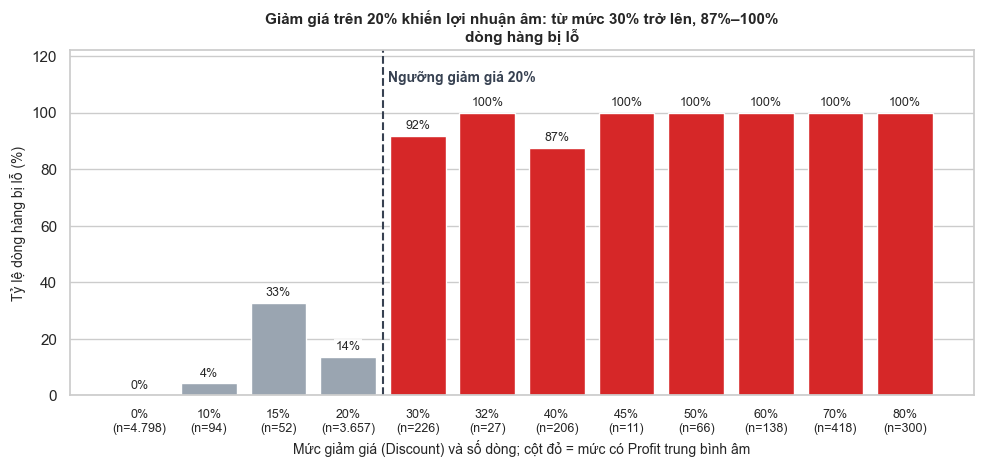

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_11_discount_loss_rate.png


**Nhận xét.** Đến mức giảm 20%, Profit trung bình vẫn dương (+24,70 USD, 13,7% dòng lỗ); từ mức 30% trở lên Profit trung bình đổi dấu (−45,83 USD) và tỷ lệ lỗ vọt lên 91,6%, rồi từ 87,4% đến 100% ở các mức cao hơn. Không giảm giá thì không có dòng nào lỗ. Mức 15% chỉ có 52 dòng nên tỷ lệ lỗ 32,7% kém ổn định.

In [14]:
dsc = df.groupby("Discount").agg(so_dong=("Profit", "size"), profit_tb=("Profit", "mean"), tong_profit=("Profit", "sum"),
                                 ty_le_lo=("Profit", lambda s: 100 * (s < 0).mean()))
dsc_out = dsc.reset_index()
dsc_out.columns = ["Mức Discount", "Số dòng", "Profit trung bình", "Tổng Profit", "Tỷ lệ đơn lỗ (%)"]
dsc_out.round(2).to_csv(REPORTS / "4_1_discount_levels.csv", index=False, encoding="utf-8-sig")
display(dsc_out.round(2))

nhan_x = [f"{int(round(d * 100))}%\n(n={vn(n)})" for d, n in zip(dsc.index, dsc["so_dong"])]
fig, ax = plt.subplots(figsize=fs(12, 5.8))
ax.bar(range(len(dsc)), dsc["ty_le_lo"], color=[LOSS if v < 0 else NEUTRAL for v in dsc["profit_tb"]])
nhan_cot(ax, range(len(dsc)), dsc["ty_le_lo"], lambda v: pct(v, 0))
vi_tri = list(dsc.index).index(0.2) + 0.5
ax.axvline(vi_tri, color=INK, ls="--", lw=1.5); ax.text(vi_tri + 0.08, 111, "Ngưỡng giảm giá 20%", fontsize=10, color=INK, fontweight="bold")
ax.set_xticks(range(len(dsc))); ax.set_xticklabels(nhan_x, fontsize=9); ax.set_ylim(0, 122)
ax.set_xlabel("Mức giảm giá (Discount) và số dòng; cột đỏ = mức có Profit trung bình âm"); ax.set_ylabel("Tỷ lệ dòng hàng bị lỗ (%)")
tren = dsc[dsc.index > 0.2]; moc_dau_am = dsc.index[dsc["profit_tb"] < 0].min()
ax.set_title(f"Giảm giá trên 20% khiến lợi nhuận âm: từ mức {int(round(moc_dau_am * 100))}% trở lên, {pct(tren['ty_le_lo'].min(), 0)}–100% dòng hàng bị lỗ")
fig.tight_layout()
luu(fig, "11_discount_loss_rate")
d20 = dsc.loc[0.2]; d30 = dsc.loc[moc_dau_am]
ket_qua.update(dsc=dsc, moc_dau_am=moc_dau_am)
nhan_xet(f"Đến mức giảm 20%, Profit trung bình vẫn dương (+{vn(d20['profit_tb'], 2)} USD, {pct(d20['ty_le_lo'])} dòng lỗ); từ mức {int(round(moc_dau_am * 100))}% trở lên Profit trung bình đổi dấu ({vn(d30['profit_tb'], 2)} USD) và tỷ lệ lỗ vọt lên {pct(d30['ty_le_lo'])}, "
         f"rồi từ {pct(tren['ty_le_lo'].min())} đến 100% ở các mức cao hơn. Không giảm giá thì không có dòng nào lỗ. Mức 15% chỉ có {vn(dsc.loc[0.15, 'so_dong'])} dòng nên tỷ lệ lỗ {pct(dsc.loc[0.15, 'ty_le_lo'])} kém ổn định.")

**Kết luận cho Câu hỏi 2 – ngưỡng giảm giá bắt đầu gây lỗ:** ngưỡng nằm ở **mức giảm giá trên 20%**. Đến 20%, Profit trung bình vẫn dương; từ mức giảm 30% trở lên, Profit trung bình âm và phần lớn dòng hàng bị lỗ. Đề xuất đặt **trần khuyến mãi 20%** (quyết định sẽ được nêu ở mục 5.3).

/var/folders/8p/zwk0wgd97_bbbxh6t06xq6gr0000gn/T/ipykernel_42845/2216882433.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.axhline(0, color="black", lw=0.8); ax.set_yscale("symlog", linthresh=10); ax.set_xticklabels([f"{int(round(d * 100))}%" for d in trung_vi.index])


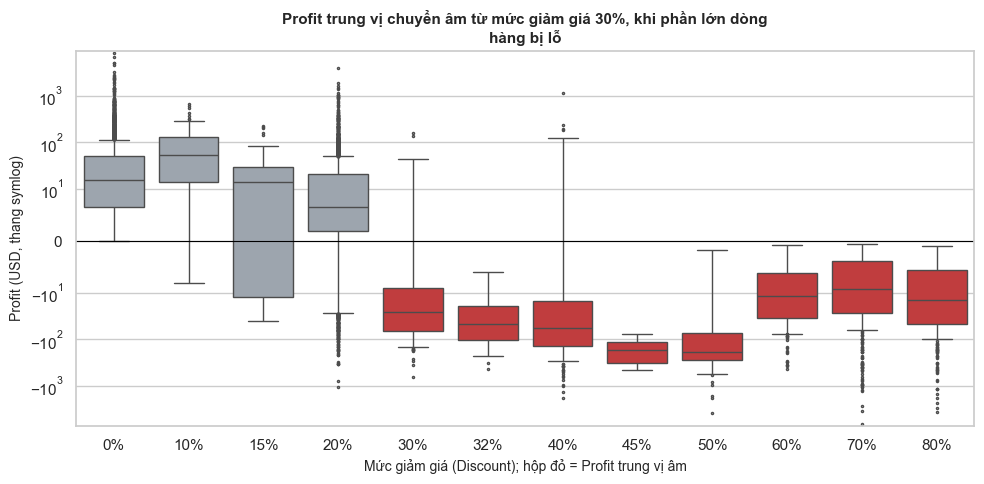

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_12_discount_boxplot.png


**Nhận xét.** Profit trung vị của các mức giảm giá đến 20% đều dương (từ 6,49 USD), còn từ mức 30% trở lên đều âm (thấp nhất −185,28 USD ở mức 50%). Sự đổi dấu này khớp với ngưỡng 20% ở hình trước.

In [15]:
fig, ax = plt.subplots(figsize=fs(12, 6))
trung_vi = df.groupby("Discount")["Profit"].median()
sns.boxplot(x="Discount", y="Profit", data=df, ax=ax, palette={d: (LOSS if trung_vi[d] < 0 else NEUTRAL) for d in trung_vi.index}, hue="Discount", legend=False,
            fliersize=1.5, linewidth=1)
ax.axhline(0, color="black", lw=0.8); ax.set_yscale("symlog", linthresh=10); ax.set_xticklabels([f"{int(round(d * 100))}%" for d in trung_vi.index])
ax.set_xlabel("Mức giảm giá (Discount); hộp đỏ = Profit trung vị âm"); ax.set_ylabel("Profit (USD, thang symlog)")
moc_tv = trung_vi.index[trung_vi < 0].min()
ax.set_title(f"Profit trung vị chuyển âm từ mức giảm giá {int(round(moc_tv * 100))}%, khi phần lớn dòng hàng bị lỗ")
fig.tight_layout()
luu(fig, "12_discount_boxplot")
nhan_xet(f"Profit trung vị của các mức giảm giá đến 20% đều dương (từ {vn(trung_vi[trung_vi.index <= 0.2].min(), 2)} USD), còn từ mức {int(round(moc_tv * 100))}% trở lên đều âm (thấp nhất {vn(trung_vi.min(), 2)} USD ở mức {int(round(trung_vi.idxmin() * 100))}%). Sự đổi dấu này khớp với ngưỡng 20% ở hình trước.")

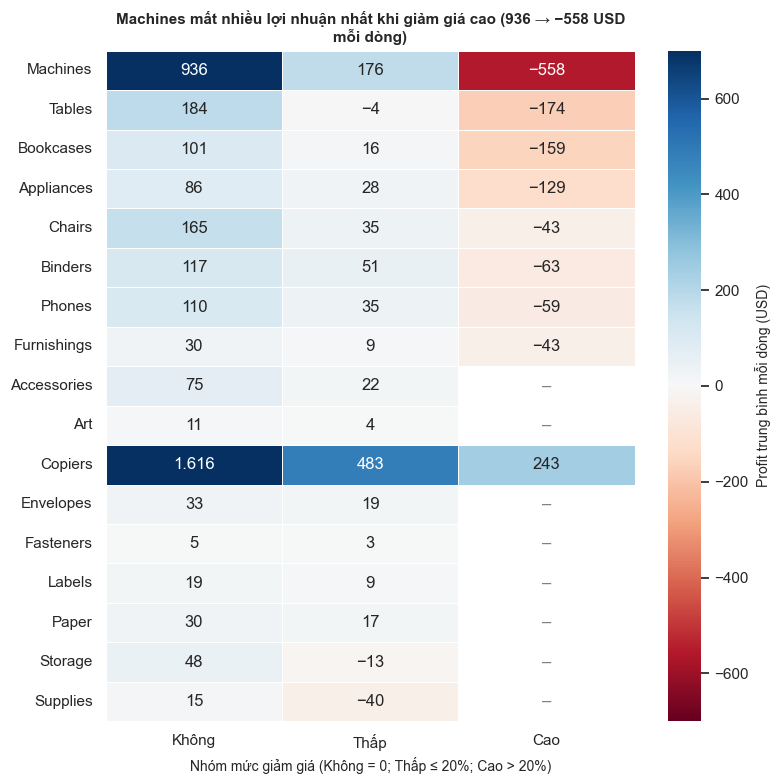

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_13_subcategory_discount_heatmap.png


**Nhận xét.** Nhóm nhạy cảm nhất với giảm giá cao là Machines (Profit trung bình mỗi dòng giảm từ 936 xuống −558 USD), tiếp theo là Tables và Bookcases. Ở mức giảm cao, 8/9 nhóm hàng có Profit trung bình âm; dấu – là ô không có dữ liệu.

In [16]:
pt = df.pivot_table(index="Sub-Category", columns="Discount_Level", values="Profit", aggfunc="mean")[["Không", "Thấp", "Cao"]]
pn = df.pivot_table(index="Sub-Category", columns="Discount_Level", values="Profit", aggfunc="size")[["Không", "Thấp", "Cao"]]
nhay = (pt["Cao"] - pt["Không"]).where(pn["Cao"] >= 20)          # chỉ xét nhóm có ít nhất 20 dòng ở mức Cao
pt = pt.loc[nhay.sort_values(na_position="last").index]
nhat = nhay.idxmin()
chu_thich = pt.copy().astype(object)
for r in pt.index:
    for c in pt.columns:
        chu_thich.loc[r, c] = "–" if np.isnan(pt.loc[r, c]) else vn(pt.loc[r, c])

fig, ax = plt.subplots(figsize=fs(8, 8))
sns.heatmap(pt, annot=chu_thich.values, fmt="", cmap="RdBu", norm=TwoSlopeNorm(vcenter=0, vmin=-700, vmax=700), linewidths=0.5, ax=ax,
            cbar_kws={"label": "Profit trung bình mỗi dòng (USD)"})
ax.grid(False)
for i, r in enumerate(pt.index):
    for j, c in enumerate(pt.columns):
        if np.isnan(pt.loc[r, c]): ax.text(j + 0.5, i + 0.5, "–", ha="center", va="center", color="gray", fontsize=12)
ax.set_xlabel("Nhóm mức giảm giá (Không = 0; Thấp ≤ 20%; Cao > 20%)"); ax.set_ylabel("")
ax.set_title(f"{nhat} mất nhiều lợi nhuận nhất khi giảm giá cao ({vn(pt.loc[nhat, 'Không'])} → {vn(pt.loc[nhat, 'Cao'])} USD mỗi dòng)", fontsize=11)
fig.tight_layout()
luu(fig, "13_subcategory_discount_heatmap")
ket_qua.update(nhat=nhat, pt=pt)
top3n = nhay.nsmallest(3)
nhan_xet(f"Nhóm nhạy cảm nhất với giảm giá cao là {nhat} (Profit trung bình mỗi dòng giảm từ {vn(pt.loc[nhat, 'Không'])} xuống {vn(pt.loc[nhat, 'Cao'])} USD), tiếp theo là {top3n.index[1]} và {top3n.index[2]}. "
         f"Ở mức giảm cao, {int((pt['Cao'] < 0).sum())}/{int(pt['Cao'].notna().sum())} nhóm hàng có Profit trung bình âm; dấu – là ô không có dữ liệu.")

,Region,Số đơn,Số đơn bị trả,Tỷ lệ đơn bị trả (%)
0,West,1611,189,11.73
1,East,1401,44,3.14
2,Central,1175,39,3.32
3,South,822,24,2.92


Toàn công ty: 296/5009 đơn = 5,9%


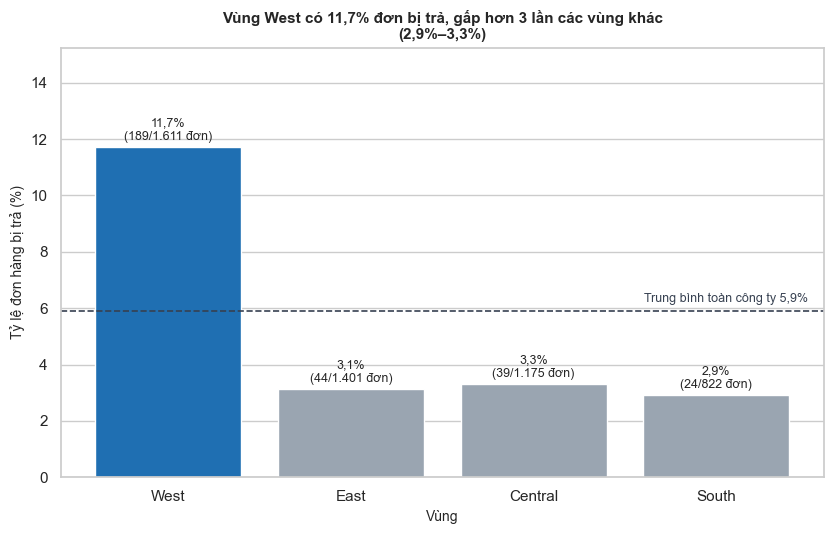

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_1_14_returns_by_region.png


**Nhận xét.** Tính ở mức đơn hàng (5.009 đơn), West có 189/1.611 đơn bị trả (11,7%), chiếm 63,9% tổng số đơn bị trả toàn công ty dù chỉ có 32,2% số đơn; ba vùng còn lại chỉ 2,9%–3,3%.

In [17]:
tra = orders.groupby("Region").agg(so_don=("Order ID", "size"), so_don_tra=("is_returned", "sum")).sort_values("so_don_tra", ascending=False)
tra["ty_le"] = 100 * tra["so_don_tra"] / tra["so_don"]
ty_le_cty = 100 * orders["is_returned"].mean()
tra_out = tra.reset_index(); tra_out.columns = ["Region", "Số đơn", "Số đơn bị trả", "Tỷ lệ đơn bị trả (%)"]
tra_out.round(2).to_csv(REPORTS / "4_1_returns_by_region.csv", index=False, encoding="utf-8-sig")
display(tra_out.round(2))
print(f"Toàn công ty: {int(orders['is_returned'].sum())}/{len(orders)} đơn = {pct(ty_le_cty)}")

fig, ax = plt.subplots(figsize=fs(8.5, 5.5))
ax.bar(tra.index, tra["ty_le"], color=[FOCUS if v == tra["ty_le"].max() else NEUTRAL for v in tra["ty_le"]])
ax.axhline(ty_le_cty, color=INK, ls="--", lw=1.2); ax.text(len(tra) - 0.5, ty_le_cty + 0.3, f"Trung bình toàn công ty {pct(ty_le_cty)}", ha="right", fontsize=9, color=INK)
for i, (t, n_, k) in enumerate(zip(tra["ty_le"], tra["so_don"], tra["so_don_tra"])):
    ax.annotate(f"{pct(t)}\n({vn(k)}/{vn(n_)} đơn)", (i, t), ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
ax.set_ylabel("Tỷ lệ đơn hàng bị trả (%)"); ax.set_xlabel("Vùng"); ax.set_ylim(0, tra["ty_le"].max() * 1.3)
khac = tra.drop("West")["ty_le"]
ax.set_title(f"Vùng West có {pct(tra.loc['West', 'ty_le'])} đơn bị trả, gấp hơn 3 lần các vùng khác ({pct(khac.min())}–{pct(khac.max())})")
fig.tight_layout()
luu(fig, "14_returns_by_region")
ket_qua.update(tra=tra, ty_le_tra_cty=ty_le_cty)
nhan_xet(f"Tính ở mức đơn hàng ({vn(len(orders))} đơn), West có {vn(tra.loc['West', 'so_don_tra'])}/{vn(tra.loc['West', 'so_don'])} đơn bị trả ({pct(tra.loc['West', 'ty_le'])}), chiếm {pct(100 * tra.loc['West', 'so_don_tra'] / tra['so_don_tra'].sum())} tổng số đơn bị trả toàn công ty "
         f"dù chỉ có {pct(100 * tra.loc['West', 'so_don'] / tra['so_don'].sum())} số đơn; ba vùng còn lại chỉ {pct(khac.min())}–{pct(khac.max())}.")

## 5. Kiểm định thống kê (α = 0,05)

**p-value** là xác suất thu được kết quả (hoặc cực đoan hơn) nếu giả thuyết không H0 đúng; p-value nhỏ hơn α = 0,05 thì bác bỏ H0.

### 5.1. Profit giữa 4 vùng: ANOVA và Kruskal–Wallis

- **ANOVA một yếu tố** so sánh **trung bình** các nhóm; cần dữ liệu xấp xỉ phân phối chuẩn và phương sai bằng nhau.
- **Kruskal–Wallis** là kiểm định phi tham số, so sánh **phân phối** (dựa trên thứ hạng) nên không đòi hỏi phân phối chuẩn.

Trước hết kiểm tra giả định.

In [18]:
nhom_vung = {r: g["Profit"].values for r, g in df.groupby("Region")}
rng = np.random.default_rng(42)
kd = []  # bảng kết quả kiểm định để lưu

hang = []
for r, x in nhom_vung.items():
    mau = rng.choice(x, size=min(2000, len(x)), replace=False)      # Shapiro–Wilk chỉ tin cậy với mẫu vừa phải
    w_, p_sw = stats.shapiro(mau); k2, p_dag = stats.normaltest(x)  # D'Agostino trên toàn bộ nhóm
    hang.append({"Vùng": r, "n": len(x), "Độ lệch": pd.Series(x).skew(), "Shapiro W (mẫu 2.000)": w_, "p Shapiro": p_sw, "D'Agostino K²": k2, "p D'Agostino": p_dag})
    kd.append({"Kiểm định": f"Shapiro–Wilk (Profit, {r}, mẫu 2.000)", "Giả thuyết H0": "Profit có phân phối chuẩn", "Thống kê": f"W = {vn(w_, 3)}", "p-value": pv(p_sw),
               "Kết luận": "Bác bỏ H0: không chuẩn" if p_sw < 0.05 else "Không bác bỏ H0"})
chuan = pd.DataFrame(hang); display(chuan.round(4))
lev, p_lev = stats.levene(*nhom_vung.values(), center="median")
print(f"Levene (đồng nhất phương sai): thống kê = {vn(lev, 2)}, p = {pv(p_lev)}")
kd.append({"Kiểm định": "Levene (Profit giữa 4 vùng)", "Giả thuyết H0": "Phương sai Profit bằng nhau giữa các vùng", "Thống kê": f"W = {vn(lev, 2)}", "p-value": pv(p_lev),
           "Kết luận": "Bác bỏ H0: phương sai không đồng nhất" if p_lev < 0.05 else "Không bác bỏ H0"})
ket_qua.update(chuan=chuan, lev=lev, p_lev=p_lev)

,Vùng,n,Độ lệch,Shapiro W (mẫu 2.000),p Shapiro,D'Agostino K²,p D'Agostino
0,Central,2323,12.8481,0.2359,0.0,4263.4967,0.0
1,East,2847,-0.7513,0.3092,0.0,1556.2851,0.0
2,South,1620,-0.8181,0.3297,0.0,835.4564,0.0
3,West,3203,16.7675,0.3415,0.0,6648.6106,0.0


Levene (đồng nhất phương sai): thống kê = 5,58, p = 8,02 × 10⁻⁴


In [19]:
F, p_f = stats.f_oneway(*nhom_vung.values())
H, p_h = stats.kruskal(*nhom_vung.values())
n_tong, k = len(df), len(nhom_vung); eta_h = (H - k + 1) / (n_tong - k)
print(f"ANOVA một yếu tố: F = {vn(F, 2)}, p = {pv(p_f)}")
print(f"Kruskal–Wallis:   H = {vn(H, 1)}, p = {pv(p_h)} | mức độ ảnh hưởng η²_H = {vn(eta_h, 3)}")
tb = df.groupby("Region")["Profit"].agg(["mean", "median"]).round(2); display(tb)
kd.append({"Kiểm định": "ANOVA một yếu tố (Profit ~ Region)", "Giả thuyết H0": "Trung bình Profit bằng nhau giữa 4 vùng", "Thống kê": f"F = {vn(F, 2)}",
           "p-value": pv(p_f), "Kết luận": "Bác bỏ H0 sát ngưỡng (p ≈ 0,05); kém tin cậy vì giả định bị vi phạm" if p_f < 0.05 else "Không bác bỏ H0"})
kd.append({"Kiểm định": "Kruskal–Wallis (Profit ~ Region)", "Giả thuyết H0": "Phân phối Profit giống nhau giữa 4 vùng", "Thống kê": f"H = {vn(H, 1)}",
           "p-value": pv(p_h), "Kết luận": "Bác bỏ H0: Profit khác nhau giữa các vùng (ảnh hưởng nhỏ, η²_H = " + vn(eta_h, 3) + ")" if p_h < 0.05 else "Không bác bỏ H0"})
ket_qua.update(F=F, p_f=p_f, H=H, p_h=p_h, eta_h=eta_h)

ANOVA một yếu tố: F = 2,62, p = 0,049
Kruskal–Wallis:   H = 227,8, p = 4,06 × 10⁻⁴⁹ | mức độ ảnh hưởng η²_H = 0,023


,mean,median
Region,,
Central,17.09,5.18
East,32.15,8.19
South,28.86,9.07
West,33.85,11.17


**Kết luận dựa trên Kruskal–Wallis**, vì Profit không phân phối chuẩn (Shapiro–Wilk và D'Agostino đều bác bỏ H0 ở mọi vùng, độ lệch lớn) và phương sai giữa các vùng không đồng nhất (Levene bác bỏ H0).

**Vì sao hai kiểm định cho kết quả khác nhau?** ANOVA chỉ so sánh **trung bình** nên bị ảnh hưởng mạnh bởi các giá trị ngoại lai và phương sai lớn của Profit: sự khác biệt trung bình giữa các vùng là nhỏ so với độ phân tán nên chỉ đạt p ≈ 0,049, sát ngưỡng 0,05 và kém tin cậy vì giả định bị vi phạm. Kruskal–Wallis dựa trên **thứ hạng** nên bền với ngoại lai và phát hiện được sự khác biệt về toàn bộ phân phối (p cực nhỏ). Kích thước hiệu ứng nhỏ (η²_H ≈ 0,02) cho thấy vùng chỉ giải thích một phần rất nhỏ biến thiên của Profit dù khác biệt có ý nghĩa thống kê.

### 5.2. Kiểm định hậu kiểm (post-hoc) Mann–Whitney với hiệu chỉnh Bonferroni

Vì Kruskal–Wallis có ý nghĩa, so sánh từng cặp vùng bằng Mann–Whitney U. Khi thực hiện 6 cặp cùng lúc, p-value được **hiệu chỉnh Bonferroni** (nhân với 6, tối đa bằng 1) để kiểm soát xác suất kết luận sai.

In [20]:
from itertools import combinations
hau = []
for a, b in combinations(nhom_vung, 2):
    U, p_ = stats.mannwhitneyu(nhom_vung[a], nhom_vung[b], alternative="two-sided")
    p_adj = min(1.0, p_ * 6)
    r_rb = 2 * U / (len(nhom_vung[a]) * len(nhom_vung[b])) - 1        # hệ số tương quan hạng nhị phân
    hau.append({"Cặp vùng": f"{a} – {b}", "U": U, "p thô": p_, "p hiệu chỉnh (Bonferroni)": p_adj, "Có ý nghĩa (α = 0,05)": "Có" if p_adj < 0.05 else "Không", "Hiệu ứng r": r_rb})
    kd.append({"Kiểm định": f"Mann–Whitney (hậu kiểm) {a} – {b}", "Giả thuyết H0": f"Phân phối Profit của {a} và {b} giống nhau", "Thống kê": f"U = {vn(U)}",
               "p-value": pv(p_adj) + " (đã hiệu chỉnh)", "Kết luận": "Khác biệt có ý nghĩa" if p_adj < 0.05 else "Không có ý nghĩa"})
hau = pd.DataFrame(hau)
hien = hau.copy(); hien["p thô"] = hien["p thô"].map(pv); hien["p hiệu chỉnh (Bonferroni)"] = hien["p hiệu chỉnh (Bonferroni)"].map(pv); hien["U"] = hien["U"].map(lambda v: vn(v)); hien["Hiệu ứng r"] = hien["Hiệu ứng r"].map(lambda v: vn(v, 3))
display(hien)
ket_qua["hau"] = hau

,Cặp vùng,U,p thô,p hiệu chỉnh (Bonferroni),"Có ý nghĩa (α = 0,05)",Hiệu ứng r
0,Central – East,2.893.756,"1,02 × 10⁻¹⁴","6,11 × 10⁻¹⁴",Có,"−0,125"
1,Central – South,1.560.137,"6,17 × 10⁻²⁰","3,70 × 10⁻¹⁹",Có,"−0,171"
2,Central – West,2.850.007,"5,46 × 10⁻⁵⁰","3,28 × 10⁻⁴⁹",Có,"−0,234"
3,East – South,2.209.116,"0,019","0,116",Không,"−0,042"
4,East – West,4.063.127,"2,49 × 10⁻¹³","1,49 × 10⁻¹²",Có,"−0,109"
5,South – West,2.423.208,"1,78 × 10⁻⁴","0,001",Có,"−0,066"


### 5.3. Chi-square độc lập giữa Returned và Region (mức đơn hàng)

**Chi-square (χ²) kiểm tra tính độc lập** giữa hai biến phân loại: H0 là hai biến độc lập (tỷ lệ trả hàng như nhau ở mọi vùng). **Cramér's V** (từ 0 đến 1) đo độ mạnh của mối liên hệ.

**Vì sao tính ở mức đơn hàng, không phải mức dòng sản phẩm?** Các dòng thuộc cùng một đơn luôn có cùng trạng thái trả hàng, nên chúng **không độc lập** với nhau. Nếu đếm theo dòng, một đơn bị trả có nhiều dòng sẽ bị đếm lặp và làm χ² bị **thổi phồng**. Ô sau minh họa sự chênh lệch.

In [21]:
bang_cheo = pd.crosstab(orders["Region"], orders["is_returned"].map({0: "Không trả", 1: "Bị trả"}))
chi2, p_c, dof, ky_vong = stats.chi2_contingency(bang_cheo)
n_don = bang_cheo.values.sum(); v_cramer = np.sqrt(chi2 / (n_don * (min(bang_cheo.shape) - 1)))
print("Bảng chéo (mức đơn hàng):"); display(bang_cheo)
print("Bảng chéo (tỷ lệ % theo vùng):"); display((100 * bang_cheo.div(bang_cheo.sum(axis=1), axis=0)).round(1))
print(f"χ² = {vn(chi2, 1)}, bậc tự do = {dof}, p = {pv(p_c)}, Cramér's V = {vn(v_cramer, 3)}; tần suất kỳ vọng nhỏ nhất = {vn(ky_vong.min(), 1)} (đủ điều kiện dùng χ²)")

chi2_dong, p_dong, _, _ = stats.chi2_contingency(pd.crosstab(df["Region"], df["is_returned"]))
print(f"Minh họa – nếu tính sai ở mức dòng sản phẩm ({vn(len(df))} dòng): χ² = {vn(chi2_dong, 1)} (gấp {vn(chi2_dong / chi2, 1)} lần mức đơn hàng)")
kd.append({"Kiểm định": "Chi-square độc lập (Returned × Region, mức đơn hàng)", "Giả thuyết H0": "Trả hàng độc lập với vùng", "Thống kê": f"χ² = {vn(chi2, 1)}, df = {dof}",
           "p-value": pv(p_c), "Kết luận": f"Bác bỏ H0: tỷ lệ trả hàng khác nhau giữa các vùng (Cramér's V = {vn(v_cramer, 2)}, hiệu ứng nhỏ đến trung bình)" if p_c < 0.05 else "Không bác bỏ H0"})
ket_qua.update(chi2=chi2, dof=dof, p_chi=p_c, v_cramer=v_cramer, chi2_dong=chi2_dong)

bang_kd = pd.DataFrame(kd, columns=["Kiểm định", "Giả thuyết H0", "Thống kê", "p-value", "Kết luận"])
bang_kd.to_csv(REPORTS / "4_1_statistical_tests.csv", index=False, encoding="utf-8-sig")
hau.to_csv(REPORTS / "4_1_posthoc_mannwhitney.csv", index=False, encoding="utf-8-sig")
print("Đã lưu:", REPORTS / "4_1_statistical_tests.csv")
display(bang_kd)

Bảng chéo (mức đơn hàng):


is_returned,Bị trả,Không trả
Region,,
Central,39,1136
East,44,1357
South,24,798
West,189,1422


Bảng chéo (tỷ lệ % theo vùng):


is_returned,Bị trả,Không trả
Region,,
Central,3.3,96.7
East,3.1,96.9
South,2.9,97.1
West,11.7,88.3


χ² = 144,9, bậc tự do = 3, p = 3,26 × 10⁻³¹, Cramér's V = 0,170; tần suất kỳ vọng nhỏ nhất = 48,6 (đủ điều kiện dùng χ²)
Minh họa – nếu tính sai ở mức dòng sản phẩm (9.993 dòng): χ² = 343,5 (gấp 2,4 lần mức đơn hàng)
Đã lưu: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/reports/4_1_statistical_tests.csv


,Kiểm định,Giả thuyết H0,Thống kê,p-value,Kết luận
0,"Shapiro–Wilk (Profit, Central, mẫu 2.000)",Profit có phân phối chuẩn,"W = 0,236","1,63 × 10⁻⁶⁷",Bác bỏ H0: không chuẩn
1,"Shapiro–Wilk (Profit, East, mẫu 2.000)",Profit có phân phối chuẩn,"W = 0,309","1,36 × 10⁻⁶⁵",Bác bỏ H0: không chuẩn
2,"Shapiro–Wilk (Profit, South, mẫu 2.000)",Profit có phân phối chuẩn,"W = 0,330","1,54 × 10⁻⁶⁰",Bác bỏ H0: không chuẩn
3,"Shapiro–Wilk (Profit, West, mẫu 2.000)",Profit có phân phối chuẩn,"W = 0,342","1,09 × 10⁻⁶⁴",Bác bỏ H0: không chuẩn
4,Levene (Profit giữa 4 vùng),Phương sai Profit bằng nhau giữa các vùng,"W = 5,58","8,02 × 10⁻⁴",Bác bỏ H0: phương sai không đồng nhất
5,ANOVA một yếu tố (Profit ~ Region),Trung bình Profit bằng nhau giữa 4 vùng,"F = 2,62","0,049","Bác bỏ H0 sát ngưỡng (p ≈ 0,05); kém tin cậy v..."
6,Kruskal–Wallis (Profit ~ Region),Phân phối Profit giống nhau giữa 4 vùng,"H = 227,8","4,06 × 10⁻⁴⁹",Bác bỏ H0: Profit khác nhau giữa các vùng (ảnh...
7,Mann–Whitney (hậu kiểm) Central – East,Phân phối Profit của Central và East giống nhau,U = 2.893.756,"6,11 × 10⁻¹⁴ (đã hiệu chỉnh)",Khác biệt có ý nghĩa
8,Mann–Whitney (hậu kiểm) Central – South,Phân phối Profit của Central và South giống nhau,U = 1.560.137,"3,70 × 10⁻¹⁹ (đã hiệu chỉnh)",Khác biệt có ý nghĩa
9,Mann–Whitney (hậu kiểm) Central – West,Phân phối Profit của Central và West giống nhau,U = 2.850.007,"3,28 × 10⁻⁴⁹ (đã hiệu chỉnh)",Khác biệt có ý nghĩa


## 6. Tổng hợp insight

Các insight dưới đây được tạo trực tiếp từ kết quả ở trên (nên số liệu luôn khớp). Số hình `Hình 4.x` là số hình trong báo cáo (xem bảng ánh xạ ở cuối file).

In [22]:
tk, ts = tt["Category"], tt["Region"]
loss_states = ket_qua["bang_state"][ket_qua["bang_state"]["Profit"] < 0]
dsc = ket_qua["dsc"]
bao = ["Insight {n} – {ten}: {so}. Ý nghĩa kinh doanh: {y}."]
insights = [
    ("Furniture kéo thấp lợi nhuận của cả công ty (trả lời Câu hỏi 1)",
     f"Furniture chiếm {pct(tk.loc['Furniture', 'Tỷ trọng Sales (%)'])} doanh thu nhưng chỉ {pct(tk.loc['Furniture', 'Tỷ trọng Profit (%)'])} lợi nhuận, biên chỉ {pct(tk.loc['Furniture', 'Profit Margin (%)'])} so với {pct(tk.loc['Technology', 'Profit Margin (%)'])} của Technology và {pct(tk.loc['Office Supplies', 'Profit Margin (%)'])} của Office Supplies (Hình 4.4)",
     "cần rà soát giá bán, chiết khấu và giá vốn của Furniture trước khi mở rộng doanh số ngành này"),
    ("Chỉ ba nhóm hàng bị lỗ và Tables chiếm phần lớn (trả lời Câu hỏi 1)",
     f"{len(sub_lo)}/17 nhóm hàng có Profit âm: {', '.join(f'{i} ({vn(v)} USD)' for i, v in sub_lo['Profit'].items())}; riêng Tables chiếm {pct(100 * sub_lo.loc['Tables', 'Profit'] / sub_lo['Profit'].sum())} tổng lỗ của ba nhóm (Hình 4.5)",
     "ưu tiên xử lý Tables (điều chỉnh giá, hạn chế giảm giá hoặc cân nhắc ngừng bán), sau đó Bookcases và Supplies"),
    ("Central kém hiệu quả nhất và 10 bang bị lỗ (trả lời Câu hỏi 1)",
     f"Central có biên {pct(ts.loc['Central', 'Profit Margin (%)'])} so với West {pct(ts.loc['West', 'Profit Margin (%)'])}; {n_bang_lo}/{len(ket_qua['bang_state'])} bang lỗ với tổng lỗ {vn(loss_states['Profit'].sum())} USD, nặng nhất {', '.join(f'{i} ({vn(v)})' for i, v in loss_states['Profit'].head(3).items())} (Hình 4.4, 4.6)",
     "cần điều tra nguyên nhân lỗ ở các bang này (giảm giá, cơ cấu sản phẩm, chi phí vận chuyển) thay vì áp dụng chính sách chung"),
    ("Giảm giá trên 20% khiến lợi nhuận âm (trả lời Câu hỏi 2)",
     f"đến mức giảm 20% Profit trung bình còn +{vn(dsc.loc[0.2, 'profit_tb'], 2)} USD ({pct(dsc.loc[0.2, 'ty_le_lo'])} dòng lỗ); từ mức {int(round(moc_dau_am * 100))}% trở lên Profit trung bình âm ({vn(dsc.loc[moc_dau_am, 'profit_tb'], 2)} USD) và {pct(dsc[dsc.index > 0.2]['ty_le_lo'].min())}–100% dòng bị lỗ; nhóm giảm giá cao (trên 20%) có tổng Profit {vn(df.loc[df['Discount'] > 0.2, 'Profit'].sum())} USD trong khi nhóm không giảm giá lãi {vn(df.loc[df['Discount'] == 0, 'Profit'].sum())} USD (Hình 4.8)",
     "nên đặt trần khuyến mãi ở mức 20%"),
    ("Tác động của giảm giá là quan hệ phi tuyến (trả lời Câu hỏi 2)",
     f"Discount–Profit chỉ {vn(r_p, 2)} theo Pearson nhưng {vn(r_s, 2)} theo Spearman vì lợi nhuận đổi dấu ở ngưỡng chứ không giảm đều theo đường thẳng (Hình 4.7)",
     "khi đánh giá khuyến mãi nên phân tích theo ngưỡng thay vì dựa vào hệ số tương quan tuyến tính"),
    ("Nhóm hàng nhạy cảm nhất với giảm giá cao (trả lời Câu hỏi 2)",
     f"{nhat} giảm từ {vn(pt.loc[nhat, 'Không'])} xuống {vn(pt.loc[nhat, 'Cao'])} USD Profit trung bình mỗi dòng khi chuyển từ không giảm giá sang giảm giá cao; ở mức giảm cao {int((pt['Cao'] < 0).sum())}/{int(pt['Cao'].notna().sum())} nhóm hàng có Profit trung bình âm (Hình 4.9)",
     "trần khuyến mãi cần chặt hơn với các nhóm hàng nhạy cảm này"),
    ("Doanh thu mang tính mùa vụ rõ rệt",
     f"Q4 chiếm {pct(quy_tt[4])} doanh thu, Q3 {pct(quy_tt[3])}, còn Q1 chỉ {pct(quy_tt[1])}; tháng {top_thang.index[0]} cao nhất ({pct(top_thang.iloc[0])}), tiếp theo tháng {top_thang.index[1]} và {top_thang.index[2]}; chỉ {len(thang_lo)} tháng lỗ ({', '.join(f'{t:%m/%Y}' for t in thang_lo.index)}) (Hình 4.2, 4.3)",
     "cần chuẩn bị tồn kho và nhân lực trước quý 3–4, đồng thời tránh khuyến mãi sâu vào mùa cao điểm vì doanh thu đã tự tăng"),
    ("Vùng West có tỷ lệ đơn bị trả cao bất thường",
     f"{pct(tra.loc['West', 'ty_le'])} đơn ở West bị trả ({vn(tra.loc['West', 'so_don_tra'])}/{vn(tra.loc['West', 'so_don'])}) so với {pct(khac.min())}–{pct(khac.max())} ở các vùng khác; kiểm định χ² = {vn(chi2, 1)}, df = {dof}, p {'< 0,001' if p_c < 0.001 else '= ' + pv(p_c)}, Cramér's V = {vn(v_cramer, 2)} (Hình 4.10)",
     "cần tìm nguyên nhân trả hàng ở West (chất lượng giao hàng, chính sách đổi trả, cơ cấu sản phẩm)"),
]
ban_do_hinh = [("Hình 4.1", "01_univariate_grid", "Phân bố đơn biến (Sales, Profit, Discount, Quantity)"),
               ("Hình 4.2", "02_monthly_trend", "Doanh thu và lợi nhuận theo tháng"),
               ("Hình 4.3", "04_seasonality", "Mùa vụ theo quý và theo tháng"),
               ("Hình 4.4", "05_margin_by_group", "Biên lợi nhuận theo Region, Segment, Category"),
               ("Hình 4.5", "07_subcategory_profit", "Profit theo Sub-Category"),
               ("Hình 4.6", "08_state_top_bottom", "Top 10 và bottom 10 bang theo Profit"),
               ("Hình 4.7", "10_correlation", "Ma trận tương quan Pearson và Spearman"),
               ("Hình 4.8", "11_discount_loss_rate", "Tỷ lệ dòng lỗ theo mức Discount"),
               ("Hình 4.9", "13_subcategory_discount_heatmap", "Heatmap Sub-Category × Discount_Level"),
               ("Hình 4.10", "14_returns_by_region", "Tỷ lệ đơn bị trả theo Region"),
               ("Phụ lục P.1", "03_year_summary", "Doanh thu và lợi nhuận theo năm"),
               ("Phụ lục P.2", "06_share_sales_vs_profit", "Tỷ trọng Sales so với Profit"),
               ("Phụ lục P.3", "09_pareto", "Pareto lợi nhuận theo sản phẩm"),
               ("Phụ lục P.4", "12_discount_boxplot", "Boxplot Profit theo mức Discount")]
noi_dung = "# Insight mục 4.1 – Phân tích khám phá dữ liệu Superstore\n\n"
for n, (ten, so, y) in enumerate(insights, 1):
    noi_dung += f"{n}. **Insight {n} – {ten}:** {so}. Ý nghĩa kinh doanh: {y}.\n\n"
noi_dung += "## Bảng ánh xạ hình (số hình trong báo cáo ↔ file)\n\n| Số hình | File | Nội dung |\n|---|---|---|\n"
noi_dung += "".join(f"| {h} | `figures/4_1_{f}.png` | {t} |\n" for h, f, t in ban_do_hinh)
(REPORTS / "4_1_insights.md").write_text(noi_dung, encoding="utf-8")
print("Đã lưu:", REPORTS / "4_1_insights.md", "| số insight:", len(insights))
display(Markdown(noi_dung))

Đã lưu: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/reports/4_1_insights.md | số insight: 8


# Insight mục 4.1 – Phân tích khám phá dữ liệu Superstore

1. **Insight 1 – Furniture kéo thấp lợi nhuận của cả công ty (trả lời Câu hỏi 1):** Furniture chiếm 32,3% doanh thu nhưng chỉ 6,4% lợi nhuận, biên chỉ 2,5% so với 17,4% của Technology và 17,0% của Office Supplies (Hình 4.4). Ý nghĩa kinh doanh: cần rà soát giá bán, chiết khấu và giá vốn của Furniture trước khi mở rộng doanh số ngành này.

2. **Insight 2 – Chỉ ba nhóm hàng bị lỗ và Tables chiếm phần lớn (trả lời Câu hỏi 1):** 3/17 nhóm hàng có Profit âm: Tables (−17.725 USD), Bookcases (−3.473 USD), Supplies (−1.189 USD); riêng Tables chiếm 79,2% tổng lỗ của ba nhóm (Hình 4.5). Ý nghĩa kinh doanh: ưu tiên xử lý Tables (điều chỉnh giá, hạn chế giảm giá hoặc cân nhắc ngừng bán), sau đó Bookcases và Supplies.

3. **Insight 3 – Central kém hiệu quả nhất và 10 bang bị lỗ (trả lời Câu hỏi 1):** Central có biên 7,9% so với West 14,9%; 10/49 bang lỗ với tổng lỗ −98.235 USD, nặng nhất Texas (−25.729), Ohio (−16.959), Pennsylvania (−15.560) (Hình 4.4, 4.6). Ý nghĩa kinh doanh: cần điều tra nguyên nhân lỗ ở các bang này (giảm giá, cơ cấu sản phẩm, chi phí vận chuyển) thay vì áp dụng chính sách chung.

4. **Insight 4 – Giảm giá trên 20% khiến lợi nhuận âm (trả lời Câu hỏi 2):** đến mức giảm 20% Profit trung bình còn +24,70 USD (13,7% dòng lỗ); từ mức 30% trở lên Profit trung bình âm (−45,83 USD) và 87,4%–100% dòng bị lỗ; nhóm giảm giá cao (trên 20%) có tổng Profit −135.364 USD trong khi nhóm không giảm giá lãi 320.988 USD (Hình 4.8). Ý nghĩa kinh doanh: nên đặt trần khuyến mãi ở mức 20%.

5. **Insight 5 – Tác động của giảm giá là quan hệ phi tuyến (trả lời Câu hỏi 2):** Discount–Profit chỉ −0,22 theo Pearson nhưng −0,54 theo Spearman vì lợi nhuận đổi dấu ở ngưỡng chứ không giảm đều theo đường thẳng (Hình 4.7). Ý nghĩa kinh doanh: khi đánh giá khuyến mãi nên phân tích theo ngưỡng thay vì dựa vào hệ số tương quan tuyến tính.

6. **Insight 6 – Nhóm hàng nhạy cảm nhất với giảm giá cao (trả lời Câu hỏi 2):** Machines giảm từ 936 xuống −558 USD Profit trung bình mỗi dòng khi chuyển từ không giảm giá sang giảm giá cao; ở mức giảm cao 8/9 nhóm hàng có Profit trung bình âm (Hình 4.9). Ý nghĩa kinh doanh: trần khuyến mãi cần chặt hơn với các nhóm hàng nhạy cảm này.

7. **Insight 7 – Doanh thu mang tính mùa vụ rõ rệt:** Q4 chiếm 38,2% doanh thu, Q3 26,7%, còn Q1 chỉ 15,7%; tháng 11 cao nhất (15,3%), tiếp theo tháng 12 và 9; chỉ 2 tháng lỗ (07/2016, 01/2017) (Hình 4.2, 4.3). Ý nghĩa kinh doanh: cần chuẩn bị tồn kho và nhân lực trước quý 3–4, đồng thời tránh khuyến mãi sâu vào mùa cao điểm vì doanh thu đã tự tăng.

8. **Insight 8 – Vùng West có tỷ lệ đơn bị trả cao bất thường:** 11,7% đơn ở West bị trả (189/1.611) so với 2,9%–3,3% ở các vùng khác; kiểm định χ² = 144,9, df = 3, p < 0,001, Cramér's V = 0,17 (Hình 4.10). Ý nghĩa kinh doanh: cần tìm nguyên nhân trả hàng ở West (chất lượng giao hàng, chính sách đổi trả, cơ cấu sản phẩm).

## Bảng ánh xạ hình (số hình trong báo cáo ↔ file)

| Số hình | File | Nội dung |
|---|---|---|
| Hình 4.1 | `figures/4_1_01_univariate_grid.png` | Phân bố đơn biến (Sales, Profit, Discount, Quantity) |
| Hình 4.2 | `figures/4_1_02_monthly_trend.png` | Doanh thu và lợi nhuận theo tháng |
| Hình 4.3 | `figures/4_1_04_seasonality.png` | Mùa vụ theo quý và theo tháng |
| Hình 4.4 | `figures/4_1_05_margin_by_group.png` | Biên lợi nhuận theo Region, Segment, Category |
| Hình 4.5 | `figures/4_1_07_subcategory_profit.png` | Profit theo Sub-Category |
| Hình 4.6 | `figures/4_1_08_state_top_bottom.png` | Top 10 và bottom 10 bang theo Profit |
| Hình 4.7 | `figures/4_1_10_correlation.png` | Ma trận tương quan Pearson và Spearman |
| Hình 4.8 | `figures/4_1_11_discount_loss_rate.png` | Tỷ lệ dòng lỗ theo mức Discount |
| Hình 4.9 | `figures/4_1_13_subcategory_discount_heatmap.png` | Heatmap Sub-Category × Discount_Level |
| Hình 4.10 | `figures/4_1_14_returns_by_region.png` | Tỷ lệ đơn bị trả theo Region |
| Phụ lục P.1 | `figures/4_1_03_year_summary.png` | Doanh thu và lợi nhuận theo năm |
| Phụ lục P.2 | `figures/4_1_06_share_sales_vs_profit.png` | Tỷ trọng Sales so với Profit |
| Phụ lục P.3 | `figures/4_1_09_pareto.png` | Pareto lợi nhuận theo sản phẩm |
| Phụ lục P.4 | `figures/4_1_12_discount_boxplot.png` | Boxplot Profit theo mức Discount |


### Kiểm tra lại các file đã lưu và đối chiếu kết quả kỳ vọng

In [23]:
import glob
hinh = sorted(glob.glob(str(FIGURES / "4_1_*.png")))
print("Số hình 4_1_*.png:", len(hinh))
assert 12 <= len(hinh) <= 15
for ten in ["4_1_descriptive_stats", "4_1_statistical_tests", "4_1_year_summary", "4_1_group_summary", "4_1_discount_levels", "4_1_returns_by_region"]:
    assert (REPORTS / f"{ten}.csv").exists(), ten
assert (REPORTS / "4_1_insights.md").exists()

nam, tt, dsc, tra = ket_qua["nam"], ket_qua["tt"], ket_qua["dsc"], ket_qua["tra"]
g = "Tăng trưởng Sales so với năm trước (%)"
gan = lambda a, b, tol: abs(a - b) <= tol
kiem_tra = {
    "Tổng Sales ≈ 2.296.919; tổng Profit ≈ 286.409; biên ≈ 12,5%": gan(ket_qua["tong_sales"], 2296919, 1) and gan(ket_qua["tong_profit"], 286409, 1) and gan(100 * ket_qua["bien_cty"], 12.5, 0.05),
    "Độ lệch: Sales 12,97; Profit 7,56": gan(ket_qua["skew_sales"], 12.97, 0.01) and gan(ket_qua["skew_profit"], 7.56, 0.01),
    "2016: 483.966 / 49.556 / 10,2%": gan(nam.loc[2016, "Sales"], 483966, 1) and gan(nam.loc[2016, "Profit"], 49556, 1) and gan(nam.loc[2016, "Profit Margin (%)"], 10.2, 0.05),
    "2017: 470.533 / 61.619 / 13,1% (Sales −2,8%)": gan(nam.loc[2017, "Sales"], 470533, 1) and gan(nam.loc[2017, "Profit"], 61619, 1) and gan(nam.loc[2017, "Profit Margin (%)"], 13.1, 0.05) and gan(nam.loc[2017, g], -2.8, 0.05),
    "2018: 609.206 / 81.795 / 13,4% (+29,5%)": gan(nam.loc[2018, "Sales"], 609206, 1) and gan(nam.loc[2018, "Profit"], 81795, 1) and gan(nam.loc[2018, "Profit Margin (%)"], 13.4, 0.05) and gan(nam.loc[2018, g], 29.5, 0.05),
    "2019: 733.215 / 93.439 / 12,7% (+20,4%)": gan(nam.loc[2019, "Sales"], 733215, 1) and gan(nam.loc[2019, "Profit"], 93439, 1) and gan(nam.loc[2019, "Profit Margin (%)"], 12.7, 0.05) and gan(nam.loc[2019, g], 20.4, 0.05),
    "Tỷ trọng quý: Q1 15,7 / Q2 19,4 / Q3 26,7 / Q4 38,2": all(gan(ket_qua["quy_tt"][q], v, 0.05) for q, v in zip([1, 2, 3, 4], [15.7, 19.4, 26.7, 38.2])),
    "Tháng cao nhất: 11 (15,3%), 12 (14,2%), 9 (13,4%)": list(ket_qua["top_thang"].index) == [11, 12, 9] and all(gan(a, b, 0.05) for a, b in zip(ket_qua["top_thang"].values, [15.3, 14.2, 13.4])),
    "Tháng lợi nhuận âm: 07/2016, 01/2017": ket_qua["thang_lo"] == ["07/2016", "01/2017"],
    "Biên Region: West 14,9; East 13,5; South 11,9; Central 7,9": all(gan(tt["Region"].loc[r, "Profit Margin (%)"], v, 0.05) for r, v in {"West": 14.9, "East": 13.5, "South": 11.9, "Central": 7.9}.items()),
    "Biên Category: Technology 17,4; Office Supplies 17,0; Furniture 2,5": all(gan(tt["Category"].loc[r, "Profit Margin (%)"], v, 0.05) for r, v in {"Technology": 17.4, "Office Supplies": 17.0, "Furniture": 2.5}.items()),
    "Sub-Category lỗ: Tables ≈ −17.725; Bookcases ≈ −3.473; Supplies ≈ −1.189": (ket_qua["sub_lo"]["Profit"].round(0).to_dict() == {"Tables": -17725.0, "Bookcases": -3473.0, "Supplies": -1189.0}),
    "State: 10 bang lỗ; Texas ≈ −25.729, Ohio ≈ −16.959, Pennsylvania ≈ −15.560": ket_qua["n_bang_lo"] == 10 and ket_qua["bang_state"]["Profit"].round(0).head(3).to_dict() == {"Texas": -25729.0, "Ohio": -16959.0, "Pennsylvania": -15560.0},
    "State lãi nhất: California ≈ 76.381; New York ≈ 74.039": ket_qua["bang_state"]["Profit"].round(0).tail(2).to_dict() == {"New York": 74039.0, "California": 76381.0},
    "Discount–Profit: Pearson ≈ −0,22; Spearman ≈ −0,54": gan(ket_qua["r_pearson"], -0.22, 0.005) and gan(ket_qua["r_spearman"], -0.54, 0.005),
    "Trả hàng: West 11,7% (189/1.611); Central 3,3; East 3,1; South 2,9; toàn công ty 5,9": (tra.loc["West", "so_don_tra"] == 189 and tra.loc["West", "so_don"] == 1611 and gan(tra.loc["West", "ty_le"], 11.7, 0.05)
        and all(gan(tra.loc[r, "ty_le"], v, 0.05) for r, v in {"Central": 3.3, "East": 3.1, "South": 2.9}.items()) and gan(ket_qua["ty_le_tra_cty"], 5.9, 0.05)),
    "ANOVA: F ≈ 2,62; p ≈ 0,049": gan(ket_qua["F"], 2.62, 0.01) and gan(ket_qua["p_f"], 0.049, 0.001),
    "Kruskal–Wallis: H ≈ 227,8; p ≈ 4×10⁻⁴⁹": gan(ket_qua["H"], 227.8, 0.05) and 3.5e-49 < ket_qua["p_h"] < 4.5e-49,
    "Chi-square: χ² ≈ 144,9; df = 3; p ≈ 3×10⁻³¹": gan(ket_qua["chi2"], 144.9, 0.05) and ket_qua["dof"] == 3 and 2.5e-31 < ket_qua["p_chi"] < 3.5e-31,
}
for ten, ok in kiem_tra.items():
    print("ĐẠT " if ok else "LỆCH", "–", ten)
assert all(kiem_tra.values()), "Có kết quả lệch so với kỳ vọng, cần kiểm tra lại"
print()
print("Tất cả kết quả khớp kỳ vọng.")

Số hình 4_1_*.png: 14
ĐẠT  – Tổng Sales ≈ 2.296.919; tổng Profit ≈ 286.409; biên ≈ 12,5%
ĐẠT  – Độ lệch: Sales 12,97; Profit 7,56
ĐẠT  – 2016: 483.966 / 49.556 / 10,2%
ĐẠT  – 2017: 470.533 / 61.619 / 13,1% (Sales −2,8%)
ĐẠT  – 2018: 609.206 / 81.795 / 13,4% (+29,5%)
ĐẠT  – 2019: 733.215 / 93.439 / 12,7% (+20,4%)
ĐẠT  – Tỷ trọng quý: Q1 15,7 / Q2 19,4 / Q3 26,7 / Q4 38,2
ĐẠT  – Tháng cao nhất: 11 (15,3%), 12 (14,2%), 9 (13,4%)
ĐẠT  – Tháng lợi nhuận âm: 07/2016, 01/2017
ĐẠT  – Biên Region: West 14,9; East 13,5; South 11,9; Central 7,9
ĐẠT  – Biên Category: Technology 17,4; Office Supplies 17,0; Furniture 2,5
ĐẠT  – Sub-Category lỗ: Tables ≈ −17.725; Bookcases ≈ −3.473; Supplies ≈ −1.189
ĐẠT  – State: 10 bang lỗ; Texas ≈ −25.729, Ohio ≈ −16.959, Pennsylvania ≈ −15.560
ĐẠT  – State lãi nhất: California ≈ 76.381; New York ≈ 74.039
ĐẠT  – Discount–Profit: Pearson ≈ −0,22; Spearman ≈ −0,54
ĐẠT  – Trả hàng: West 11,7% (189/1.611); Central 3,3; East 3,1; South 2,9; toàn công ty 5,9
ĐẠT  – ANOV